## SwiGLU 9 results: local fitting at 1B tokens and calibration scaling

Load-only analysis of the completed SwiGLU-9 runs; it loads no model and trains nothing. Every derived value is recomputed from the run records and cross-checked against `part-b-summary-001` and `block-check-001` at the end. Design, results, and interpretation are in `docs/experiments/model/swiglu/swiglu-9.md`.

| Quantity | Definition | Type |
| --- | --- | --- |
| Gap g | (slice-only − fitted) / fitted, on the 8K KL at 1B (verdict) or the monitoring KL (curves) | Project-defined, decision log 2026-10-17 |
| Twin noise | Largest relative difference between the two fitted-50% runs over the 25M checkpoints from 500M to 1B and the final 8K KL; SwiGLU-7's run is the denominator | Project-defined, decision log 2026-10-17 |
| Closing point | First checkpoint after which the monitoring gap stays below 5% until 1B | Project-defined, decision log 2026-10-17 |
| Token equivalent T(t), raw | Slice-only tokens at which its monitoring KL first reaches the fitted KL at checkpoint t, interpolated linearly between checkpoints | Project-defined, decision log 2026-10-17 |
| Token equivalent T(t), best-so-far | As raw, with the lowest fitted KL reached by t as the target and the slice-only running minimum as the curve | Project-defined (analysis choice, 2026-10-18) |
| Net saving N(t) | T(t) − t − C · r, with C the local-fit seconds of the target's allocation and r the slice-only recovery tokens per second; C excludes activation capture, so N is an upper bound | Project-defined (analysis choice, 2026-10-18) |
| Part A reduction | 1 − KL(setting) / mean KL of SwiGLU-8 `c1e-3-128` over seeds 21-23; seed noise 2·SD / mean | Project-defined, SwiGLU-8 adoption rule and decision log 2026-10-17 |
| L2-SP penalty | Ω(w) = (α/2)‖w − w⁰‖² | Source-derived: `src-l2-sp-2018`, Section 3, Eq. (2) |
| L2-SP strength | α = 2ρ · ΔMSE / d², ρ = 0.1 (weak) or 1 (strong) | Project-defined, decision log 2026-10-17 |
| Predicted pull | A quadratic training MSE along the fit direction puts the L2-SP minimum at 1/(1+ρ) of the fit's distance, so the squared-distance ratio is 1/(1+ρ)² | Standard mathematics (one-dimensional quadratic model), no citation |

setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter, NullLocator

# Seaborn's default theme; constrained layout keeps panel titles, legends and notes from overlapping.
sns.set_theme(rc={'figure.dpi': 120, 'figure.constrained_layout.use': True})

In [2]:
PROJECT_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'mlp_replacement').is_dir()
)
S9_RESULTS = PROJECT_ROOT / 'data/results/workflows/model/swiglu-9'
S8_RESULTS = PROJECT_ROOT / 'data/results/workflows/model/swiglu-8'
S7_RESULTS = PROJECT_ROOT / 'data/results/workflows/model/swiglu-7'
TARGETS = (0.2, 0.5, 0.8)
ARMS = ('fitted', 'slice')
# Part B models (decision log, 2026-10-17): SwiGLU-7's S7-0 1B runs are the fitted 20% and 50% arms, and the new
# fitted 50% run is their noise twin.
REUSED_FITTED_TARGETS = (0.2, 0.5)
TWIN = ('fitted', 0.5)
S9_RUN_PATHS = {
    (arm, target): S9_RESULTS / f'{arm}-target-{target}-1b-run-001/result.json'
    for arm, target in (('fitted', 0.5), ('fitted', 0.8), ('slice', 0.2), ('slice', 0.5), ('slice', 0.8))
}
S7_RUN_PATHS = {target: S7_RESULTS / f'S7-0-target-{target}-run-001/result.json' for target in REUSED_FITTED_TARGETS}
# SwiGLU-8's 100M runs from the same token-0 starts, for the 100M-to-1B comparison.
S8_RUN_PATHS = {(arm, target): S8_RESULTS / f'{arm}-target-{target}-run-001/result.json'
                for arm in ARMS for target in TARGETS}
REFERENCE_KL_PATH = S9_RESULTS / 'reference-kl-001/result.json'
PART_B_SUMMARY_PATH = S9_RESULTS / 'part-b-summary-001/result.json'
BLOCK_CHECK_PATH = S9_RESULTS / 'block-check-001/result.json'
S8_BLOCK_CHECK_PATH = S8_RESULTS / 'block-check-001/result.json'  # Part A reference: c1e-3-128 at seeds 21-23
S8_PREPARED_PATH = S8_RESULTS / 'prepare-001/result.json'  # allocations and local-fit seconds

ORIGINAL_WIDTH = 8192
REVIEW_LIMIT = 0.01  # C2 and B2 are recorded and reviewed against 1% (swiglu-9.md, acceptance checks)
SHOWN_TOKENS = (0, 10_000_000, 25_000_000, 50_000_000, 100_000_000, 500_000_000, 1_000_000_000)
EQUIVALENT_TOKENS = (100_000_000, 250_000_000, 500_000_000, 750_000_000, 1_000_000_000)
LATE_WINDOW = (600_000_000, 1_000_000_000)  # late monitoring-gap range reported in swiglu-9.md
REFERENCE_SETTING = 'c1e-3-128'
REFERENCE_SEEDS = (21, 22, 23)
REPRODUCTION_SETTING = 'mse-393k'  # seed-21 refit of SwiGLU-8's cell; not an adoption candidate
CONTEXTS = {128: '128', 8192: '8K'}
# Pre-run plan and job requests (swiglu-9.md, "Pre-run resource plan"): 1 H200 and 8 CPUs per job.
PLANNED_GPU_HOURS = {'block-check': (2.5, 7), 'train': (48, 55), 'reference-kl': (0.1, 0.3)}
REQUESTED_HOURS = {'block-check': 6, 'train': 14, 'reference-kl': 1}
REQUESTED_RAM_GB = {'block-check': 128, 'train': 64, 'reference-kl': 64}
CPUS_PER_JOB = 8

ARM_LABELS = {'fitted': 'Fitted', 'slice': 'Slice only'}
ARM_COLORS = {'fitted': '#0072B2', 'slice': '#D55E00'}
TARGET_COLORS = dict(zip(TARGETS, plt.get_cmap('viridis')(np.linspace(0.0, 0.85, len(TARGETS)))))
LOSS_LABELS = {'mse': 'MSE', 'l2sp-weak': 'L2-SP weak', 'l2sp-strong': 'L2-SP strong'}
LOSS_COLORS = {'mse': '#0072B2', 'l2sp-weak': '#009E73', 'l2sp-strong': '#CC79A7'}
EQUIVALENT_COLORS = {'Raw': '#8c8c8c', 'Best-so-far': '#D55E00'}
DENSE_COLOR = '#444444'
NOTE_COLOR = '#777777'

In [3]:
def load_artifact(path, workflow, command):
    artifact = json.loads(path.read_text(encoding='utf-8'))
    if (artifact.get('workflow'), artifact.get('command')) != (workflow, command):
        raise ValueError(f'Unexpected artifact: {path}')
    return artifact


def requested_tokens(row):
    tokens = row['requested_tokens']
    return max(tokens) if isinstance(tokens, list) else tokens


def workflow_hours(artifact):
    span = pd.Timestamp(artifact['updated_at_utc']) - pd.Timestamp(artifact['created_at_utc'])
    return span.total_seconds() / 3600


def relative_difference(value, reference):
    # As swiglu_8.relative_difference: absolute difference over the reference.
    return abs(value - reference) / abs(reference)


def acceptance_frame(groups, stage, run='-'):
    return pd.DataFrame([
        {
            'Stage': stage, 'Run': run, 'Group': group, 'Metric': check.get('metric') or check['check'],
            'Layer': check.get('layer'), 'Width': check.get('width'), 'Tokens': check.get('tokens'),
            'Value': check['value'], 'Reference': check.get('reference'),
            'Relative difference': check.get('relative_difference'), 'Tolerance': check.get('tolerance'),
            'Passed': bool(check['passed']),
        }
        for group, summary in groups.items() for check in summary['checks']
    ])


def show_table(frame, caption, formats=None):
    display(
        frame.style.hide(axis='index').format(formats or {}, na_rep='-').set_caption(caption)
        .set_table_styles([
            {'selector': 'caption',
             'props': 'caption-side: top; text-align: left; font-weight: bold; padding: 4px 0 8px;'},
            {'selector': 'th', 'props': 'text-align: left;'},
        ])
    )


runs = {key: load_artifact(path, 'swiglu-9', 'train') for key, path in S9_RUN_PATHS.items()}
swiglu7_runs = {target: load_artifact(path, 'swiglu-7', 'train') for target, path in S7_RUN_PATHS.items()}
swiglu8_runs = {key: load_artifact(path, 'swiglu-8', 'train') for key, path in S8_RUN_PATHS.items()}
for (arm, target), run in [*runs.items(), *swiglu8_runs.items()]:
    if (run['identity']['arm'], run['identity']['target']) != (arm, target):
        raise ValueError(f"Artifact identity mismatch: {run['identity']}")
for target, run in swiglu7_runs.items():
    if run['identity'] != {'strategy': 'S7-0', 'target': target}:
        raise ValueError(f"Artifact identity mismatch: {run['identity']}")
reference_kl = load_artifact(REFERENCE_KL_PATH, 'swiglu-9', 'reference-kl')
summary = load_artifact(PART_B_SUMMARY_PATH, 'swiglu-9', 'summarize-part-b')
block_check = load_artifact(BLOCK_CHECK_PATH, 'swiglu-9', 'block-check')
swiglu8_block_check = load_artifact(S8_BLOCK_CHECK_PATH, 'swiglu-8', 'block-check')
swiglu8_prepared = load_artifact(S8_PREPARED_PATH, 'swiglu-8', 'prepare')

summary_results = summary['results']
block_results = block_check['results']
part_b = summary['configuration']['part_b']
part_a = block_check['configuration']['part_a']
GAP_BAR = part_b['verdict']['gap_bar']
NOISE_WINDOW = tuple(part_b['verdict']['noise_window_tokens'])
VALIDATION_INTERVAL = summary['configuration']['recovery']['validation_interval_tokens']
ADOPTION_RULE = part_a['adoption']

acceptance_df = pd.concat([
    *(acceptance_frame(groups, 'Part A block check', f'layer {layer}') for layer, groups in block_results['acceptance'].items()),
    acceptance_frame(reference_kl['results']['acceptance'], 'Reference KL'),
    *(acceptance_frame(run['results']['acceptance'], 'Part B recovery', f'{arm} {target:.0%}')
      for (arm, target), run in runs.items()),
], ignore_index=True)


def acceptance_text(stage):
    rows = acceptance_df[acceptance_df['Stage'] == stage]
    return ' · '.join(
        f"{group} {int(group_rows['Passed'].sum())}/{len(group_rows)}"
        for group, group_rows in rows.groupby('Group', sort=False)
    )


run_status = pd.Series([run['status'] for run in runs.values()]).value_counts()
show_table(pd.DataFrame([
    {'Stage': 'Part A block check', 'Artifacts': f"merge + {len(block_results['tasks'])} tasks",
     'Status': block_check['status'],
     'Contents': f"{len(block_results['fits'])} fits, {len(block_results['slices'])} unfitted slices",
     'Checks within tolerance': acceptance_text('Part A block check')},
    {'Stage': 'Reference KL', 'Artifacts': '1', 'Status': reference_kl['status'],
     'Contents': f"8K KL of SwiGLU-7's S7-0 1B models at {', '.join(f'{float(t):.0%}' for t in reference_kl['results']['targets'])}",
     'Checks within tolerance': acceptance_text('Reference KL')},
    {'Stage': 'Part B recovery', 'Artifacts': f'{len(runs)} runs',
     'Status': ', '.join(f'{count} {status}' for status, count in run_status.items()),
     'Contents': '1B tokens each: fitted 80%, slice only 20/50/80%, fitted-50% twin',
     'Checks within tolerance': acceptance_text('Part B recovery')},
    {'Stage': 'Part B summary', 'Artifacts': '1', 'Status': summary['status'],
     'Contents': 'stored verdict, curves, and token equivalents; recomputed below', 'Checks within tolerance': '-'},
    {'Stage': 'Reused inputs', 'Artifacts': f'{len(swiglu7_runs) + len(swiglu8_runs) + 2}',
     'Status': ', '.join(sorted({run['status'] for run in [*swiglu7_runs.values(), *swiglu8_runs.values()]})),
     'Contents': f'SwiGLU-7 S7-0 1B runs at 20/50%; SwiGLU-8 100M runs, block check, and prepare',
     'Checks within tolerance': '-'},
]), 'Loaded artifacts. C2 and B2 are 1% review limits, not stops; the two C2 flags are the 50M transient below')
print(f'Verdict bar {GAP_BAR:.0%}; noise window {NOISE_WINDOW[0] / 1e6:.0f}M-{NOISE_WINDOW[1] / 1e6:.0f}M '
      f'every {VALIDATION_INTERVAL / 1e6:.0f}M plus the final 8K KL')

Stage,Artifacts,Status,Contents,Checks within tolerance
Part A block check,merge + 3 tasks,completed,"72 fits, 6 unfitted slices",D1 21/21 · P5 3/3 · D2 3/3 · A1 6/6 · A2-A3 24/24
Reference KL,1,completed,"8K KL of SwiGLU-7's S7-0 1B models at 20%, 50%",P5 1/1
Part B recovery,5 runs,5 completed,"1B tokens each: fitted 80%, slice only 20/50/80%, fitted-50% twin",P4 5/5 · C1 10/10 · B1 2/2 · C2 43/45 · B2 48/48
Part B summary,1,completed,"stored verdict, curves, and token equivalents; recomputed below",-
Reused inputs,10,completed,"SwiGLU-7 S7-0 1B runs at 20/50%; SwiGLU-8 100M runs, block check, and prepare",-


Verdict bar 5%; noise window 500M-1000M every 25M plus the final 8K KL


part B: recomputation from the run records

In [4]:
def history_frame(artifact):
    return pd.DataFrame([
        {
            'Requested': requested_tokens(row), 'Tokens': row['actual_tokens'],
            'Monitoring KL': row['recovery_validation_kl'],
            'Monitoring PPL': (row.get('wikitext_validation') or {}).get('perplexity'),
            'Mean train KL': row['mean_train_kl'], 'Training seconds': row['training_seconds'],
        }
        for row in artifact['results']['recovery']['validation_history']
    ])


def final_kl(artifact):
    return artifact['results']['evaluation']['teacher_kl_8192']['kl']


def first_crossing(value, tokens, curve):
    # Tokens at which the curve first reaches the value, interpolated linearly between checkpoints, or NaN if it
    # never does (the rule of swiglu_9.token_equivalent).
    reached = np.flatnonzero(curve <= value)
    if not len(reached):
        return np.nan
    index = reached[0]
    if index == 0:
        return tokens[0]
    fraction = (curve[index - 1] - value) / (curve[index - 1] - curve[index])
    return tokens[index - 1] + fraction * (tokens[index] - tokens[index - 1])


def closing_point(tokens, gaps, bar):
    # First checkpoint after which the gap stays below the bar until the end; None if the last gap is not below it.
    above = np.flatnonzero(gaps >= bar)
    if not len(above):
        return tokens[0]
    return None if above[-1] == len(gaps) - 1 else tokens[above[-1] + 1]


def part_b_verdict(gap, noise, bar):
    # The decided 5% rule (decision log, 2026-10-17), as swiglu_9.part_b_verdict.
    if noise < bar:
        return 'closed' if gap < bar else 'still_matters'
    if abs(gap) <= noise:
        return 'cannot_tell'
    return 'still_matters' if gap > noise else 'outside_logged_rule'


reference_kls = {float(target): row['teacher_kl_8192']['kl'] for target, row in reference_kl['results']['targets'].items()}
fitted_artifacts = {target: swiglu7_runs[target] if target in REUSED_FITTED_TARGETS else runs[('fitted', target)]
                    for target in TARGETS}
fitted_final_kl = {target: reference_kls[target] if target in REUSED_FITTED_TARGETS else final_kl(fitted_artifacts[target])
                   for target in TARGETS}
slice_final_kl = {target: final_kl(runs[('slice', target)]) for target in TARGETS}

curve_frames = []
for target in TARGETS:
    columns = ['Requested', 'Tokens', 'Monitoring KL']
    curve = history_frame(fitted_artifacts[target])[columns].merge(
        history_frame(runs[('slice', target)])[columns], on=['Requested', 'Tokens'], suffixes=(' fitted', ' slice'))
    curve.insert(0, 'Target', target)
    curve_frames.append(curve)
curve_df = pd.concat(curve_frames, ignore_index=True).rename(
    columns={'Monitoring KL fitted': 'Fitted KL', 'Monitoring KL slice': 'Slice KL'})
curve_df['Gap'] = curve_df['Slice KL'] / curve_df['Fitted KL'] - 1
curve_df['Absolute gap'] = curve_df['Slice KL'] - curve_df['Fitted KL']

equivalent_frames = []
for target, curve in curve_df.groupby('Target'):
    tokens = curve['Tokens'].to_numpy(dtype=float)
    fitted, sliced = curve['Fitted KL'].to_numpy(), curve['Slice KL'].to_numpy()
    best_fitted, best_slice = np.minimum.accumulate(fitted), np.minimum.accumulate(sliced)
    equivalent_frames.append(curve[['Target', 'Requested', 'Tokens', 'Fitted KL']].assign(**{
        'Best fitted KL': best_fitted,
        'Raw equivalent': [first_crossing(value, tokens, sliced) for value in fitted],
        'Best-so-far equivalent': [first_crossing(value, tokens, best_slice) for value in best_fitted],
    }))
equivalent_df = pd.concat(equivalent_frames, ignore_index=True)

twin_history = history_frame(runs[TWIN]).set_index('Requested')
twin_reference_history = history_frame(swiglu7_runs[TWIN[1]]).set_index('Requested')
noise_df = pd.DataFrame([
    *({'Metric': 'monitoring KL', 'Tokens': tokens, 'Twin': twin_history.loc[tokens, 'Monitoring KL'],
       'SwiGLU-7': twin_reference_history.loc[tokens, 'Monitoring KL']}
      for tokens in range(NOISE_WINDOW[0], NOISE_WINDOW[1] + 1, VALIDATION_INTERVAL)),
    {'Metric': '8K KL (final)', 'Tokens': np.nan, 'Twin': final_kl(runs[TWIN]), 'SwiGLU-7': reference_kls[TWIN[1]]},
])
noise_df['Relative difference'] = [relative_difference(twin, reference)
                                   for twin, reference in zip(noise_df['Twin'], noise_df['SwiGLU-7'])]
twin_noise = noise_df['Relative difference'].max()
twin_gap = slice_final_kl[TWIN[1]] / final_kl(runs[TWIN]) - 1

verdict_rows = []
for target in TARGETS:
    curve = curve_df[curve_df['Target'] == target]
    gap = slice_final_kl[target] / fitted_final_kl[target] - 1
    fitted_evaluation = fitted_artifacts[target]['results']['evaluation']
    slice_evaluation = runs[('slice', target)]['results']['evaluation']
    fitted_100m, slice_100m = final_kl(swiglu8_runs[('fitted', target)]), final_kl(swiglu8_runs[('slice', target)])
    verdict_rows.append({
        'Target': target,
        'Whole-model removal': slice_evaluation['footprint']['whole_model_parameter_removal'],
        '8K KL fitted': fitted_final_kl[target], '8K KL slice only': slice_final_kl[target],
        'g @ 1B': gap, 'g @ 100M': slice_100m / fitted_100m - 1,
        'Absolute gap @ 1B': slice_final_kl[target] - fitted_final_kl[target],
        'Absolute gap @ 100M': slice_100m - fitted_100m,
        'PPL @ 8K gap': slice_evaluation['likelihood']['test-8192']['perplexity']
                        / fitted_evaluation['likelihood']['test-8192']['perplexity'] - 1,
        'Macro slice - fitted (pp)': 100 * (slice_evaluation['comparison_to_dense']['macro_accuracy']
                                            - fitted_evaluation['comparison_to_dense']['macro_accuracy']),
        'Closing point': closing_point(curve['Tokens'].to_numpy(), curve['Gap'].to_numpy(), GAP_BAR),
        'Verdict': part_b_verdict(gap, twin_noise, GAP_BAR),
        'Fitted source': 'SwiGLU-7 S7-0' if target in REUSED_FITTED_TARGETS else 'SwiGLU-9',
    })
verdict_df = pd.DataFrame(verdict_rows)
print(f'Recomputed from {len(runs)} SwiGLU-9 runs, {len(swiglu7_runs)} SwiGLU-7 runs, the reference KL and '
      f'{len(swiglu8_runs)} SwiGLU-8 runs; twin noise {twin_noise:.2%} '
      f"(largest at {noise_df.loc[noise_df['Relative difference'].idxmax(), 'Metric']}, "
      f"{noise_df.loc[noise_df['Relative difference'].idxmax(), 'Tokens'] / 1e6:.0f}M)")

Recomputed from 5 SwiGLU-9 runs, 2 SwiGLU-7 runs, the reference KL and 6 SwiGLU-8 runs; twin noise 0.31% (largest at monitoring KL, 900M)


part B, question 1: the gap at 1B against the twin noise, and the change from 100M

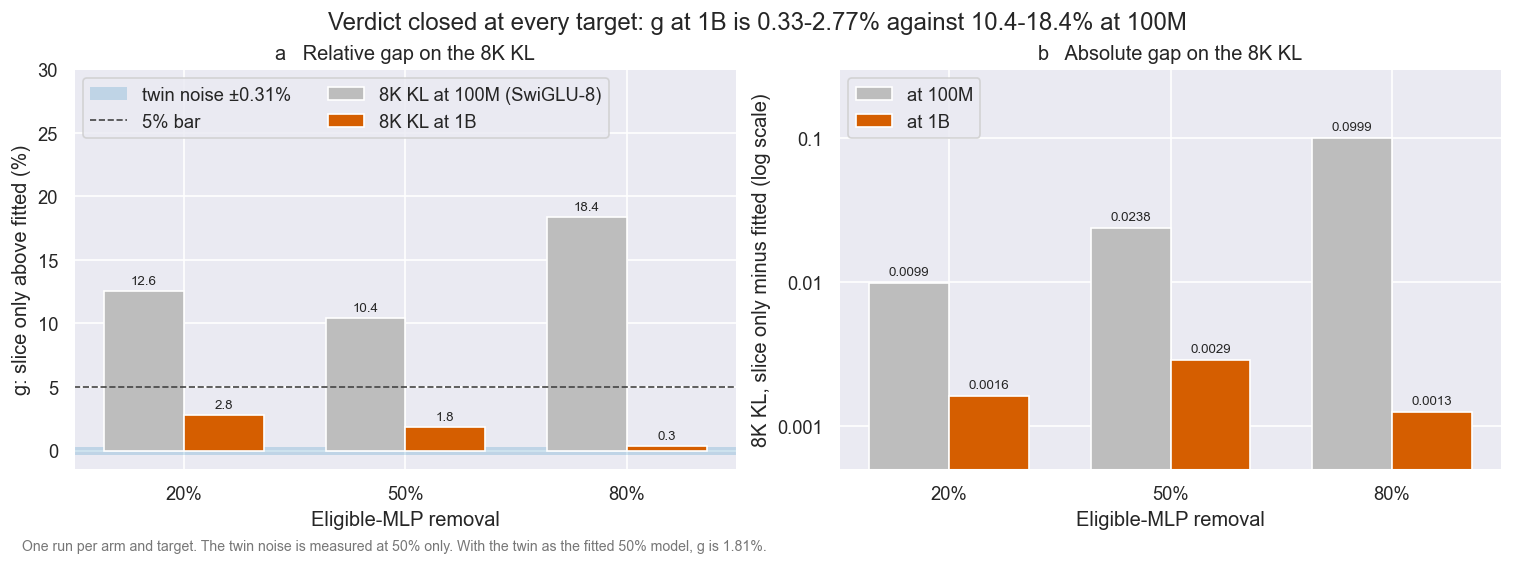

Target,Whole-model removal,8K KL fitted,8K KL slice only,g @ 1B,g @ 100M,Absolute gap @ 1B,Absolute gap @ 100M,PPL @ 8K gap,Macro slice - fitted (pp),Verdict,Fitted source
20%,12.9%,0.058213,0.059827,+2.77%,+12.6%,0.0016,0.0099,+0.12%,-0.26,closed,SwiGLU-7 S7-0
50%,32.4%,0.157788,0.160673,+1.83%,+10.4%,0.0029,0.0238,+0.11%,+0.18,closed,SwiGLU-7 S7-0
80%,51.8%,0.375228,0.376480,+0.33%,+18.4%,0.0013,0.0999,-3.50%,-0.34,closed,SwiGLU-9


In [5]:
figure, (relative_axis, absolute_axis) = plt.subplots(1, 2, figsize=(12.5, 4.4))
positions = np.arange(len(verdict_df))
bar_width = 0.36
labels = [f'{target:.0%}' for target in verdict_df['Target']]
budget_colors = {'100M': '#bdbdbd', '1B': ARM_COLORS['slice']}

relative_axis.axhspan(-100 * twin_noise, 100 * twin_noise, color=ARM_COLORS['fitted'], alpha=0.18, linewidth=0,
                      label=f'twin noise ±{twin_noise:.2%}')
relative_axis.axhline(100 * GAP_BAR, color=DENSE_COLOR, linestyle='--', linewidth=1, label=f'{GAP_BAR:.0%} bar')
for offset, (budget, column) in zip((-bar_width / 2, bar_width / 2), (('100M', 'g @ 100M'), ('1B', 'g @ 1B'))):
    values = 100 * verdict_df[column]
    relative_axis.bar(positions + offset, values, width=bar_width, color=budget_colors[budget],
                      label=f'8K KL at {budget}' + (' (SwiGLU-8)' if budget == '100M' else ''))
    for position, value in zip(positions + offset, values):
        relative_axis.text(position, value + 0.3, f'{value:.1f}', ha='center', va='bottom', fontsize=8)
relative_axis.set(ylim=(-1.5, 30), xticks=positions, xticklabels=labels, xlabel='Eligible-MLP removal',
                  ylabel='g: slice only above fitted (%)', title='a   Relative gap on the 8K KL')
relative_axis.legend(loc='upper left', ncol=2)

for offset, (budget, column) in zip((-bar_width / 2, bar_width / 2),
                                    (('100M', 'Absolute gap @ 100M'), ('1B', 'Absolute gap @ 1B'))):
    values = verdict_df[column]
    absolute_axis.bar(positions + offset, values, width=bar_width, color=budget_colors[budget], label=f'at {budget}')
    for position, value in zip(positions + offset, values):
        absolute_axis.text(position, value * 1.08, f'{value:.4f}', ha='center', va='bottom', fontsize=8)
absolute_axis.set(yscale='log', ylim=(5e-4, 0.3), xticks=positions, xticklabels=labels, xlabel='Eligible-MLP removal',
                  ylabel='8K KL, slice only minus fitted (log scale)', title='b   Absolute gap on the 8K KL')
absolute_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'))
absolute_axis.legend(loc='upper left')
verdicts = verdict_df['Verdict'].value_counts()
headline = (f'Verdict {verdicts.index[0]} at every target' if len(verdicts) == 1
            else '; '.join(f'{count} × {name}' for name, count in verdicts.items()))
figure.suptitle(
    f"{headline}: g at 1B is {100 * verdict_df['g @ 1B'].min():.2f}-{100 * verdict_df['g @ 1B'].max():.2f}% "
    f"against {100 * verdict_df['g @ 100M'].min():.1f}-{100 * verdict_df['g @ 100M'].max():.1f}% at 100M",
)
figure.text(0.01, -0.03, f'One run per arm and target. The twin noise is measured at 50% only. With the twin as the '
            f'fitted 50% model, g is {twin_gap:.2%}.', fontsize=8.5, color=NOTE_COLOR)
plt.show()

show_table(
    verdict_df.drop(columns='Closing point'),
    f'Decided rule (decision log, 2026-10-17): noise below {GAP_BAR:.0%} and g below {GAP_BAR:.0%} → closed; '
    f'twin noise {twin_noise:.2%}. Secondary metrics compare the 1B models (slice only against fitted)',
    {'Target': '{:.0%}', 'Whole-model removal': '{:.1%}', '8K KL fitted': '{:.6f}', '8K KL slice only': '{:.6f}',
     'g @ 1B': '{:+.2%}', 'g @ 100M': '{:+.1%}', 'Absolute gap @ 1B': '{:.4f}', 'Absolute gap @ 100M': '{:.4f}',
     'PPL @ 8K gap': '{:+.2%}', 'Macro slice - fitted (pp)': '{:+.2f}'},
)

part B, question 2: how fast the gap closes (monitoring KL, every 25M tokens)

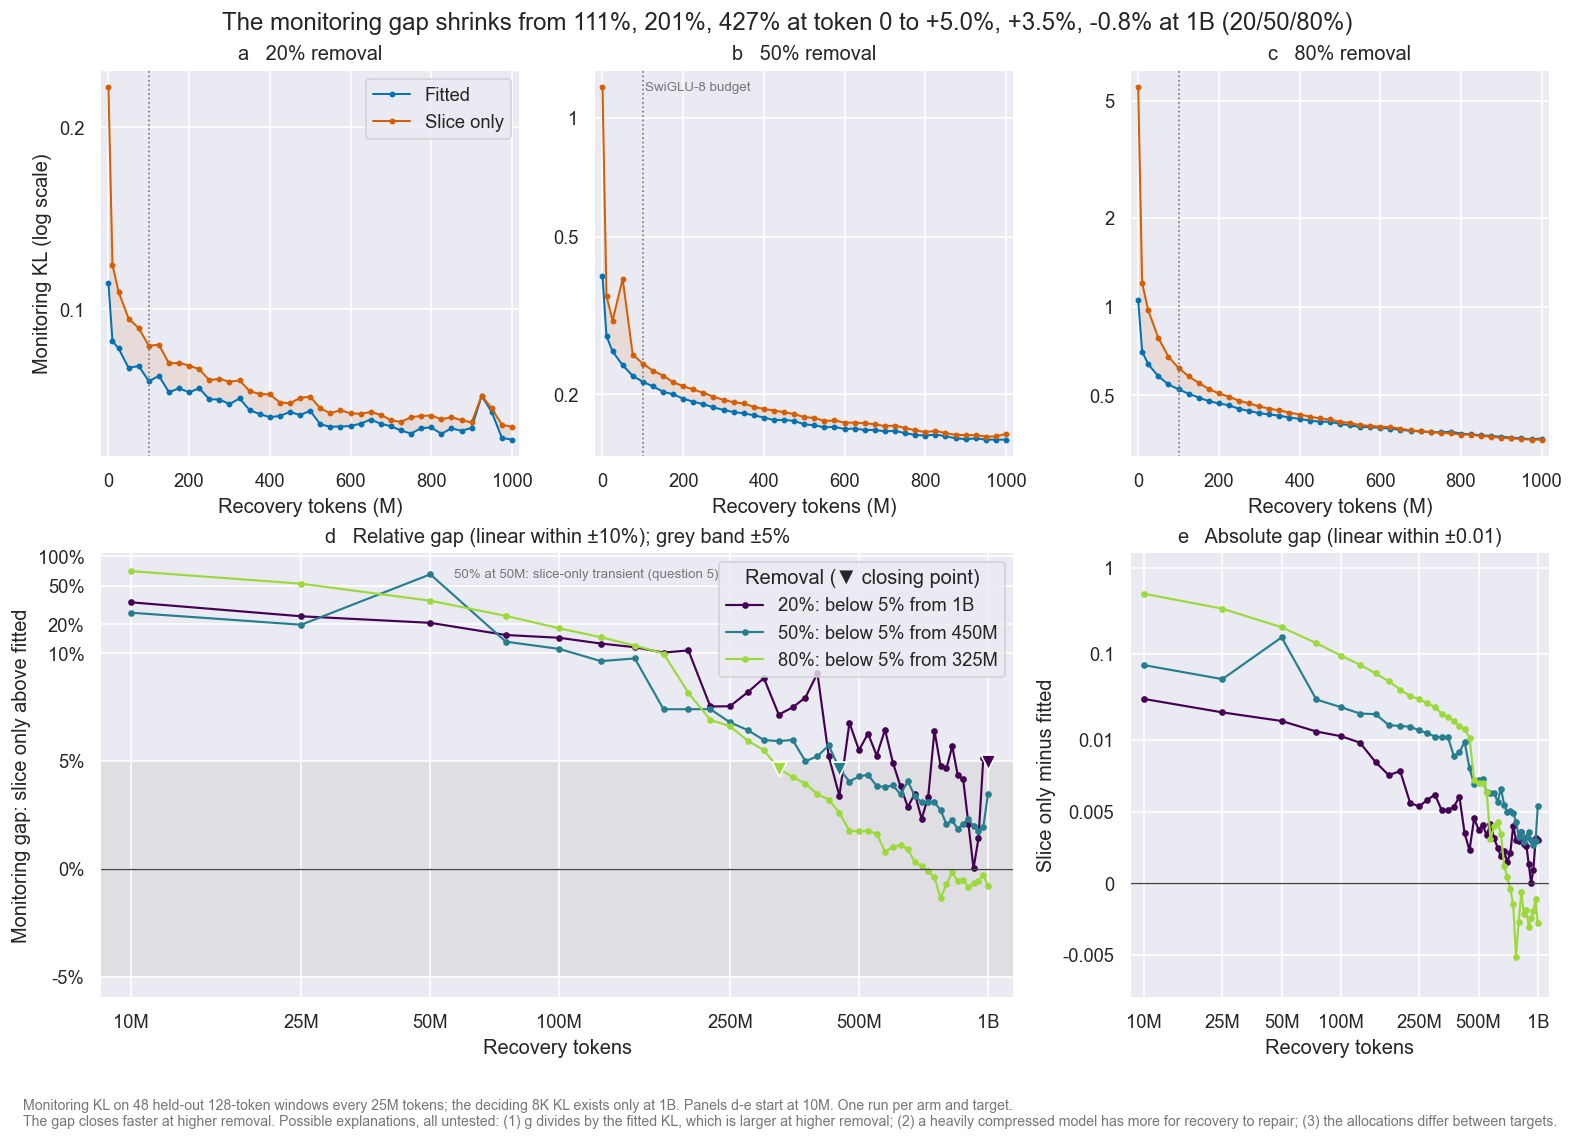

Target,Gap @ 0,Gap @ 10M,Gap @ 25M,Gap @ 50M,Gap @ 100M,Gap @ 500M,Gap @ 1B,Min 600M-1B,Max 600M-1B,Stays below 5% from
20%,+110.6%,+33.6%,+24.1%,+20.6%,+14.5%,+5.5%,+5.0%,+0.0%,+6.4%,1B
50%,+200.6%,+26.2%,+19.7%,+65.3%,+11.1%,+4.3%,+3.5%,+1.7%,+4.1%,450M
80%,+427.3%,+70.5%,+52.2%,+34.9%,+18.1%,+1.7%,-0.8%,-1.4%,+1.1%,325M


In [6]:
def token_label(value, _=None):
    return f'{value / 1e9:g}B' if value >= 1e9 else f'{value / 1e6:.0f}M'


figure = plt.figure(figsize=(13, 8.8))
grid = figure.add_gridspec(2, 3, height_ratios=(1, 1.15))
trajectory_axes = [figure.add_subplot(grid[0, column]) for column in range(3)]
gap_axis = figure.add_subplot(grid[1, :2])
absolute_axis = figure.add_subplot(grid[1, 2])
for axis, letter, target in zip(trajectory_axes, 'abc', TARGETS):
    rows = curve_df[curve_df['Target'] == target]
    tokens = rows['Tokens'] / 1e6
    axis.fill_between(tokens, rows['Fitted KL'], rows['Slice KL'], color=ARM_COLORS['slice'], alpha=0.10, linewidth=0)
    for arm, column in (('fitted', 'Fitted KL'), ('slice', 'Slice KL')):
        axis.plot(tokens, rows[column], color=ARM_COLORS[arm], marker='o', markersize=2.5, linewidth=1.2,
                  label=ARM_LABELS[arm])
    axis.axvline(100, color=NOTE_COLOR, linestyle=':', linewidth=1)
    axis.set(yscale='log', xlim=(-20, 1020), xlabel='Recovery tokens (M)', title=f'{letter}   {target:.0%} removal')
    axis.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'))
    axis.yaxis.set_minor_formatter(NullFormatter())
trajectory_axes[0].set_ylabel('Monitoring KL (log scale)')
trajectory_axes[0].legend(loc='upper right')
trajectory_axes[1].text(105, 0.97, 'SwiGLU-8 budget', transform=trajectory_axes[1].get_xaxis_transform(), fontsize=8,
                        color=NOTE_COLOR, va='top')

measured = curve_df[curve_df['Tokens'] > 0]
gap_axis.axhspan(-100 * GAP_BAR, 100 * GAP_BAR, color='#d9d9d9', alpha=0.6, linewidth=0, zorder=0)
for target, rows in measured.groupby('Target'):
    color = TARGET_COLORS[target]
    point = verdict_df.set_index('Target').loc[target, 'Closing point']
    gap_axis.plot(rows['Tokens'], 100 * rows['Gap'], color=color, marker='o', markersize=3, linewidth=1.3,
                  label=f"{target:.0%}: below {GAP_BAR:.0%} from {'never' if point is None else token_label(point)}")
    absolute_axis.plot(rows['Tokens'], rows['Absolute gap'], color=color, marker='o', markersize=3, linewidth=1.3)
    if point is not None:
        gap_axis.scatter(point, 100 * rows.loc[rows['Tokens'] == point, 'Gap'].iloc[0], marker='v', s=80, color=color,
                         edgecolor='white', zorder=5)
transient = measured[(measured['Target'] == 0.5) & (measured['Requested'] == 50_000_000)].iloc[0]
gap_axis.annotate('50% at 50M: slice-only transient (question 5)', (transient['Tokens'], 100 * transient['Gap']),
                  xytext=(14, 0), textcoords='offset points', va='center', fontsize=8, color=NOTE_COLOR)
for axis in (gap_axis, absolute_axis):
    axis.set_xscale('log')
    axis.set_xlim(8.5e6, 1.15e9)
    axis.xaxis.set_major_locator(FixedLocator([1e7, 2.5e7, 5e7, 1e8, 2.5e8, 5e8, 1e9]))
    axis.xaxis.set_major_formatter(FuncFormatter(token_label))
    axis.xaxis.set_minor_locator(NullLocator())
    axis.axhline(0, color=DENSE_COLOR, linewidth=0.8)
    axis.set_xlabel('Recovery tokens')
gap_axis.set_yscale('symlog', linthresh=10, linscale=2)
gap_axis.yaxis.set_major_locator(FixedLocator([-5, 0, 5, 10, 20, 50, 100]))
gap_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}%'))
gap_axis.yaxis.set_minor_locator(NullLocator())
gap_axis.set(ylim=(-6, 110), ylabel='Monitoring gap: slice only above fitted',
             title=f'd   Relative gap (linear within ±10%); grey band ±{GAP_BAR:.0%}')
gap_axis.legend(title='Removal (▼ closing point)', loc='upper right')
absolute_axis.set_yscale('symlog', linthresh=0.01, linscale=1.5)
absolute_axis.yaxis.set_major_locator(FixedLocator([-0.005, 0, 0.005, 0.01, 0.1, 1]))
absolute_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'))
absolute_axis.yaxis.set_minor_locator(NullLocator())
absolute_axis.set(ylim=(-0.008, 1.5), ylabel='Slice only minus fitted', title='e   Absolute gap (linear within ±0.01)')
late = measured[measured['Tokens'].between(*LATE_WINDOW)]
late_range = late.groupby('Target')['Gap'].agg(['min', 'max'])
figure.suptitle(
    'The monitoring gap shrinks from ' + ', '.join(f"{100 * curve_df[(curve_df['Target'] == t) & (curve_df['Requested'] == 0)]['Gap'].iloc[0]:.0f}%"
                                                   for t in TARGETS)
    + ' at token 0 to ' + ', '.join(f"{100 * curve_df[(curve_df['Target'] == t)]['Gap'].iloc[-1]:+.1f}%" for t in TARGETS)
    + ' at 1B (20/50/80%)',
)
figure.text(0.01, -0.06,
            'Monitoring KL on 48 held-out 128-token windows every 25M tokens; the deciding 8K KL exists only at 1B. '
            'Panels d-e start at 10M. One run per arm and target.\n'
            'The gap closes faster at higher removal. Possible explanations, all untested: (1) g divides by the fitted KL, '
            'which is larger at higher removal; (2) a heavily compressed model has more for recovery to repair; '
            '(3) the allocations differ between targets.', fontsize=8.5, color=NOTE_COLOR)
plt.show()

trajectory_table = curve_df[curve_df['Requested'].isin(SHOWN_TOKENS)].pivot(index='Target', columns='Requested', values='Gap')
trajectory_table.columns = [f'Gap @ {token_label(tokens) if tokens else "0"}' for tokens in trajectory_table.columns]
trajectory_table[f'Min {token_label(LATE_WINDOW[0])}-{token_label(LATE_WINDOW[1])}'] = late_range['min']
trajectory_table[f'Max {token_label(LATE_WINDOW[0])}-{token_label(LATE_WINDOW[1])}'] = late_range['max']
trajectory_table['Stays below 5% from'] = [
    'never' if point is None else token_label(point) for point in verdict_df.set_index('Target').loc[trajectory_table.index, 'Closing point']
]
show_table(trajectory_table.reset_index(), 'Monitoring gap (slice only - fitted) / fitted at selected checkpoints, '
           'its late range, and the closing point',
           {'Target': '{:.0%}'} | {column: '{:+.1%}' for column in trajectory_table.columns if column != 'Stays below 5% from'})

part B, question 3: recovery tokens the slice-only model needs to match the fitted model

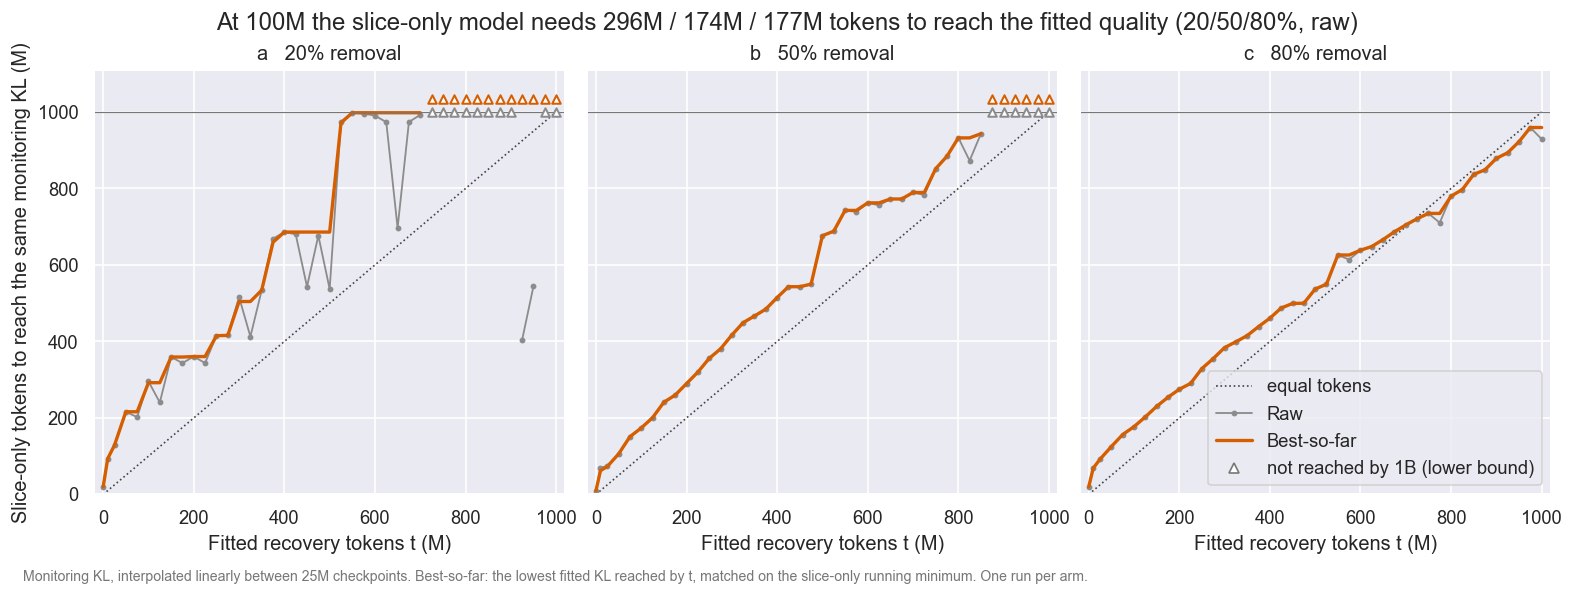

Target,Fitted tokens t (M),Fitted KL,Raw T(t) (M),Raw T(t) / t,Best fitted KL by t,Best-so-far T(t) (M),Best-so-far T(t) / t
20%,100,0.07610,296,2.96×,0.07610,292,2.92×
20%,250,0.07107,415,1.66×,0.07107,415,1.66×
20%,500,0.06803,537,1.07×,0.06638,686,1.37×
20%,750,0.06236,"> 1,000",> 1.33×,0.06236,"> 1,000",> 1.33×
20%,"1,000",0.06093,"> 1,000",> 1.00×,0.06093,"> 1,000",> 1.00×
50%,100,0.21508,174,1.74×,0.21508,174,1.74×
50%,250,0.18870,356,1.42×,0.18870,356,1.42×
50%,500,0.16779,677,1.35×,0.16779,677,1.35×
50%,750,0.15943,852,1.14×,0.15943,852,1.14×
50%,"1,000",0.15354,"> 1,000",> 1.00×,0.15353,"> 1,000",> 1.00×


In [7]:
def tokens_text(value):
    return '> 1,000' if np.isnan(value) else f'{value / 1e6:,.0f}'


def ratio_text(value, tokens, final_tokens):
    if tokens == 0:
        return '-'
    return f'> {final_tokens / tokens:.2f}×' if np.isnan(value) else f'{value / tokens:.2f}×'


final_tokens = curve_df.groupby('Target')['Tokens'].max()
figure, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for axis, letter, target in zip(axes, 'abc', TARGETS):
    rows = equivalent_df[equivalent_df['Target'] == target]
    tokens = rows['Tokens'] / 1e6
    axis.plot([0, 1000], [0, 1000], color=DENSE_COLOR, linestyle=':', linewidth=1, label='equal tokens')
    for lift, (kind, color) in zip((0, 35), EQUIVALENT_COLORS.items()):
        values = rows[f'{kind} equivalent']
        reached = values.notna()
        # NaN breaks the line where the slice-only run never reaches the fitted value.
        axis.plot(tokens, values / 1e6, color=color, linewidth=1.1 if kind == 'Raw' else 2.0,
                  marker='o' if kind == 'Raw' else None, markersize=2.5, label=kind)
        axis.scatter(tokens[~reached], np.full((~reached).sum(), final_tokens[target] / 1e6 + lift), marker='^',
                     facecolor='white', edgecolor=color, s=26, linewidth=1.2, zorder=4)
    axis.axhline(final_tokens[target] / 1e6, color=NOTE_COLOR, linewidth=0.7)
    axis.set(xlim=(-20, 1020), ylim=(0, 1110), xlabel='Fitted recovery tokens t (M)', title=f'{letter}   {target:.0%} removal')
axes[0].set_ylabel('Slice-only tokens to reach the same monitoring KL (M)')
axes[2].legend(handles=[
    *axes[2].get_legend_handles_labels()[0],
    Line2D([], [], marker='^', markerfacecolor='white', markeredgecolor=NOTE_COLOR, linestyle='none',
           label='not reached by 1B (lower bound)'),
], loc='lower right')
at_100m = equivalent_df[equivalent_df['Requested'] == 100_000_000].set_index('Target')['Raw equivalent']
figure.suptitle('At 100M the slice-only model needs ' + ' / '.join(f'{value / 1e6:.0f}M' for value in at_100m)
                + ' tokens to reach the fitted quality (20/50/80%, raw)')
figure.text(0.01, -0.04, 'Monitoring KL, interpolated linearly between 25M checkpoints. Best-so-far: the lowest fitted KL '
            'reached by t, matched on the slice-only running minimum. One run per arm.', fontsize=8.5, color=NOTE_COLOR)
plt.show()

shown = equivalent_df[equivalent_df['Requested'].isin(EQUIVALENT_TOKENS)]
show_table(pd.DataFrame([
    {
        'Target': row['Target'], 'Fitted tokens t (M)': row['Tokens'] / 1e6, 'Fitted KL': row['Fitted KL'],
        'Raw T(t) (M)': tokens_text(row['Raw equivalent']),
        'Raw T(t) / t': ratio_text(row['Raw equivalent'], row['Tokens'], final_tokens[row['Target']]),
        'Best fitted KL by t': row['Best fitted KL'],
        'Best-so-far T(t) (M)': tokens_text(row['Best-so-far equivalent']),
        'Best-so-far T(t) / t': ratio_text(row['Best-so-far equivalent'], row['Tokens'], final_tokens[row['Target']]),
    }
    for _, row in shown.iterrows()
]), "Token equivalents at selected checkpoints ('> 1,000': not reached within the 1B run)",
   {'Target': '{:.0%}', 'Fitted tokens t (M)': '{:,.0f}', 'Fitted KL': '{:.5f}', 'Best fitted KL by t': '{:.5f}'})

part B, question 4: net saving once the local-fit cost is counted

Target,Layers fitted,Fit seconds,Fit GPU-min,Slice-only tokens/s,Fit cost (M tokens)
20%,11,256,4.3,"27,153",7.0
50%,20,928,15.5,"28,366",26.3
80%,22,"2,503",41.7,"30,751",77.0


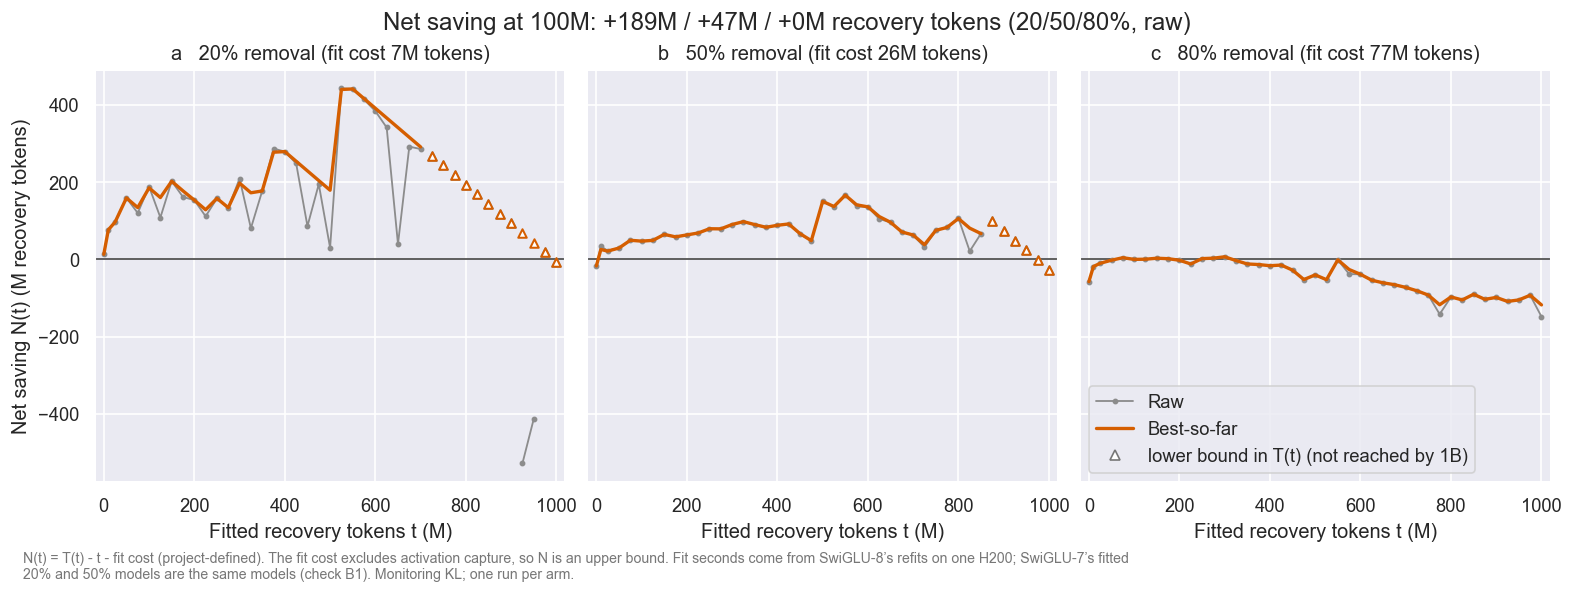

Target,Fitted tokens t (M),Raw T(t) - t (M),Raw N(t) (M),Best-so-far N(t) (M)
20%,100,+196,+189,+185
20%,250,+165,+158,+158
20%,500,+37,+30,+179
20%,750,> +250,> +243,> +243
20%,"1,000",> +0,> -7,> -7
50%,100,+74,+47,+47
50%,250,+106,+79,+79
50%,500,+177,+150,+150
50%,750,+102,+75,+75
50%,"1,000",> +0,> -26,> -26


In [8]:
fit_seconds = {(fit['layer'], fit['replacement_width']): fit['fit_seconds']
               for fit in swiglu8_prepared['results']['local_fitting']}
cost_rows = []
for target in TARGETS:
    allocation = swiglu8_prepared['results']['allocation']['targets'][str(target)]['allocation']
    fitted_layers = [row for row in allocation if row['replacement_width'] < ORIGINAL_WIDTH]
    recovery = runs[('slice', target)]['results']['recovery']
    throughput = recovery['tokens_seen'] / recovery['training_seconds']
    seconds = sum(fit_seconds[(row['layer'], row['replacement_width'])] for row in fitted_layers)
    cost_rows.append({
        'Target': target, 'Layers fitted': len(fitted_layers), 'Fit seconds': seconds, 'Fit GPU-min': seconds / 60,
        'Slice-only tokens/s': throughput, 'Fit cost (M tokens)': seconds * throughput / 1e6,
    })
cost_df = pd.DataFrame(cost_rows)
cost_tokens = equivalent_df['Target'].map(cost_df.set_index('Target')['Fit cost (M tokens)'] * 1e6)
for kind in EQUIVALENT_COLORS:
    equivalent_df[f'{kind} net saving'] = equivalent_df[f'{kind} equivalent'] - equivalent_df['Tokens'] - cost_tokens
    # Not reached within the run: the slice-only model needs more than the final tokens, so this is a lower bound.
    equivalent_df[f'{kind} net saving bound'] = np.where(
        equivalent_df[f'{kind} equivalent'].isna(),
        equivalent_df['Target'].map(final_tokens) - equivalent_df['Tokens'] - cost_tokens, np.nan)

show_table(cost_df, 'Local-fit cost per target: SwiGLU-8 prepare-001 fit seconds over the layers narrowed by the '
           'allocation, converted at the slice-only 1B run’s recovery throughput. Activation capture is not timed',
           {'Target': '{:.0%}', 'Fit seconds': '{:,.0f}', 'Fit GPU-min': '{:.1f}', 'Slice-only tokens/s': '{:,.0f}',
            'Fit cost (M tokens)': '{:.1f}'})

figure, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
for axis, letter, target in zip(axes, 'abc', TARGETS):
    rows = equivalent_df[equivalent_df['Target'] == target]
    tokens = rows['Tokens'] / 1e6
    axis.axhline(0, color=DENSE_COLOR, linewidth=1)
    for kind, color in EQUIVALENT_COLORS.items():
        axis.plot(tokens, rows[f'{kind} net saving'] / 1e6, color=color, linewidth=1.1 if kind == 'Raw' else 2.0,
                  marker='o' if kind == 'Raw' else None, markersize=2.5, label=kind)
        bounds = rows[f'{kind} net saving bound']
        axis.scatter(tokens[bounds.notna()], bounds[bounds.notna()] / 1e6, marker='^', facecolor='white',
                     edgecolor=color, s=26, linewidth=1.2, zorder=4)
    cost = cost_df.set_index('Target').loc[target, 'Fit cost (M tokens)']
    axis.set(xlim=(-20, 1020), xlabel='Fitted recovery tokens t (M)',
             title=f'{letter}   {target:.0%} removal (fit cost {cost:.0f}M tokens)')
axes[0].set_ylabel('Net saving N(t) (M recovery tokens)')
axes[2].legend(handles=[
    *axes[2].get_legend_handles_labels()[0],
    Line2D([], [], marker='^', markerfacecolor='white', markeredgecolor=NOTE_COLOR, linestyle='none',
           label='lower bound in T(t) (not reached by 1B)'),
], loc='lower left')
net_100m = equivalent_df[equivalent_df['Requested'] == 100_000_000].set_index('Target')['Raw net saving']
figure.suptitle('Net saving at 100M: ' + ' / '.join(f'{value / 1e6:+.0f}M' for value in net_100m)
                + ' recovery tokens (20/50/80%, raw)')
figure.text(0.01, -0.06, 'N(t) = T(t) - t - fit cost (project-defined). The fit cost excludes activation capture, so N is '
            'an upper bound. Fit seconds come from SwiGLU-8’s refits on one H200; SwiGLU-7’s fitted\n20% and 50% models are '
            'the same models (check B1). Monitoring KL; one run per arm.', fontsize=8.5, color=NOTE_COLOR)
plt.show()


def saving_text(value, bound):
    return f'> {bound / 1e6:+,.0f}' if np.isnan(value) else f'{value / 1e6:+,.0f}'


shown = equivalent_df[equivalent_df['Requested'].isin(EQUIVALENT_TOKENS)]
show_table(pd.DataFrame([
    {
        'Target': row['Target'], 'Fitted tokens t (M)': row['Tokens'] / 1e6,
        'Raw T(t) - t (M)': saving_text(row['Raw equivalent'] - row['Tokens'],
                                        final_tokens[row['Target']] - row['Tokens']),
        'Raw N(t) (M)': saving_text(row['Raw net saving'], row['Raw net saving bound']),
        'Best-so-far N(t) (M)': saving_text(row['Best-so-far net saving'], row['Best-so-far net saving bound']),
    }
    for _, row in shown.iterrows()
]), "Net saving at selected checkpoints, in M recovery tokens ('>': lower bound, not reached within 1B)",
   {'Target': '{:.0%}', 'Fitted tokens t (M)': '{:,.0f}'})

part B, question 5: the 50M transient in the slice-only 50% run, and the twin

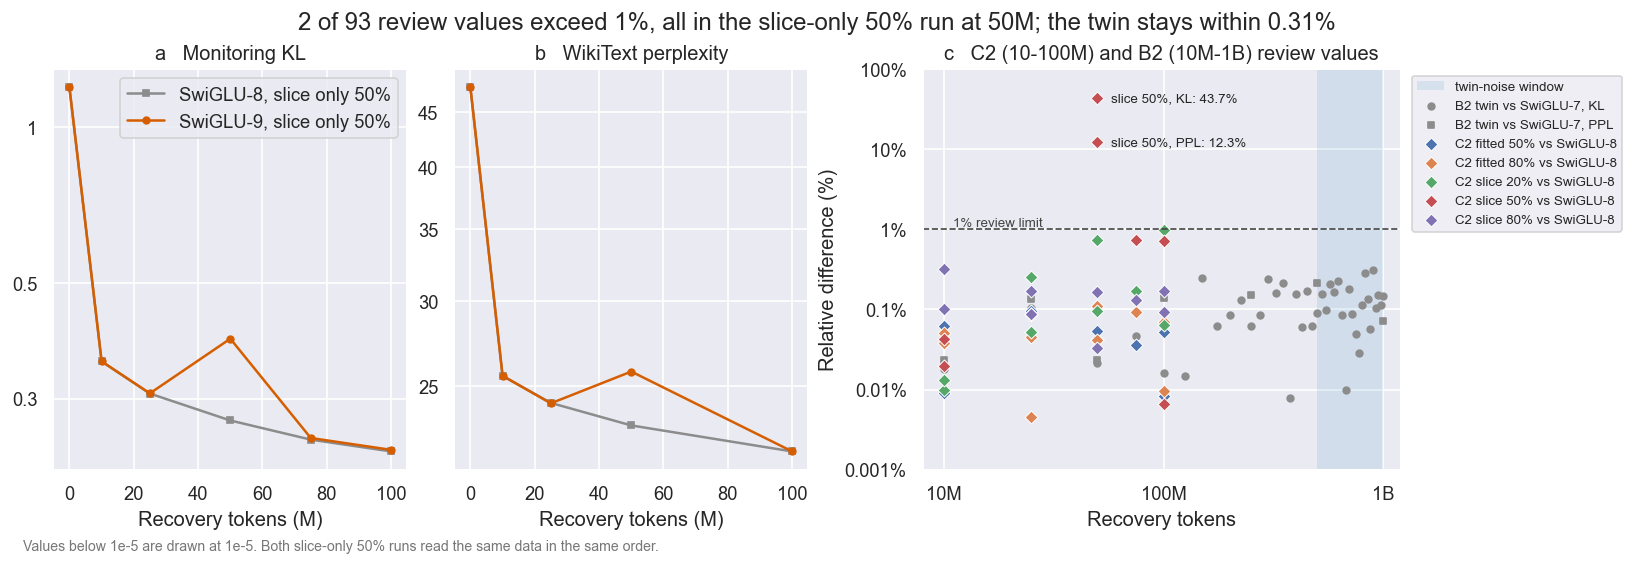

Requested,Monitoring KL SwiGLU-9,Monitoring KL SwiGLU-8,KL difference,Monitoring PPL SwiGLU-9,Monitoring PPL SwiGLU-8,Mean train KL SwiGLU-9,Mean train KL SwiGLU-8
10M,0.35386,0.35379,+0.02%,25.56,25.55,0.4449,0.4449
25M,0.30705,0.30678,+0.09%,24.09,24.11,0.3913,0.3912
50M,0.39129,0.27224,+43.73%,25.79,22.98,0.3560,0.3523
75M,0.25188,0.25005,+0.73%,-,-,0.3342,0.3314
100M,0.23897,0.23729,+0.71%,21.73,21.73,0.3187,0.3164


Quantity,Twin,SwiGLU-7,Difference
"Monitoring KL, largest over 500M-1000M",-,-,0.313%
8K KL (final),0.157819,0.157788,0.019%
Perplexity test-128,16.250588,16.259802,0.057%
Perplexity test-2048,9.405780,9.402745,0.032%
Perplexity test-8192,8.860225,8.855065,0.058%
Perplexity validation-128,16.738287,16.747012,0.052%
Perplexity validation-2048,9.602820,9.601033,0.019%
Perplexity validation-8192,9.044571,9.039976,0.051%
Accuracy arc_challenge (pp),0.360068,0.360068,+0.00 pp
Accuracy arc_easy (pp),0.633418,0.627525,+0.59 pp


Recorded environment fields that differ from SwiGLU-7's run: none


In [9]:
review_df = pd.DataFrame([
    {'Run': f'{arm} {target:.0%}', 'Group': group, 'Metric': check['metric'], 'Tokens': check['tokens'],
     'Difference': check['relative_difference'], 'Passed': check['passed']}
    for (arm, target), run in runs.items() for group in ('C2', 'B2')
    for check in run['results']['acceptance'].get(group, {}).get('checks', [])
])
swiglu9_slice = history_frame(runs[('slice', 0.5)])
swiglu8_slice = history_frame(swiglu8_runs[('slice', 0.5)])
transient_df = swiglu9_slice.merge(swiglu8_slice, on='Requested', suffixes=(' SwiGLU-9', ' SwiGLU-8'))
transient_df['KL difference'] = transient_df['Monitoring KL SwiGLU-9'] / transient_df['Monitoring KL SwiGLU-8'] - 1

figure, (kl_axis, ppl_axis, review_axis) = plt.subplots(1, 3, figsize=(13.5, 4.4),
                                                        gridspec_kw={'width_ratios': (1, 1, 1.35)})
for axis, metric, title in ((kl_axis, 'Monitoring KL', 'a   Monitoring KL'), (ppl_axis, 'Monitoring PPL', 'b   WikiText perplexity')):
    for label, color, marker in (('SwiGLU-8', '#8c8c8c', 's'), ('SwiGLU-9', ARM_COLORS['slice'], 'o')):
        rows = transient_df[transient_df[f'{metric} {label}'].notna()]
        axis.plot(rows['Requested'] / 1e6, rows[f'{metric} {label}'], color=color, marker=marker, markersize=4,
                  label=f'{label}, slice only 50%')
    axis.set(yscale='log', xlabel='Recovery tokens (M)', title=title)
    axis.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 1.5, 2.0, 3.0, 5.0)))
    axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}'))
    axis.yaxis.set_minor_formatter(NullFormatter())
kl_axis.legend(loc='upper right')

review_axis.axvspan(*NOISE_WINDOW, color=ARM_COLORS['fitted'], alpha=0.10, linewidth=0, label='twin-noise window')
review_axis.axhline(100 * REVIEW_LIMIT, color=DENSE_COLOR, linestyle='--', linewidth=1)
review_axis.text(1.1e7, 100 * REVIEW_LIMIT, f'{REVIEW_LIMIT:.0%} review limit', fontsize=8, color=DENSE_COLOR, va='bottom')
twin_review = review_df[review_df['Group'] == 'B2']
for metric, marker in (('recovery_validation_kl', 'o'), ('wikitext_validation_perplexity', 's')):
    rows = twin_review[twin_review['Metric'] == metric]
    review_axis.scatter(rows['Tokens'], 100 * rows['Difference'].clip(lower=1e-5), marker=marker, s=16, color='#8c8c8c',
                        label=f"B2 twin vs SwiGLU-7, {'KL' if metric.startswith('recovery') else 'PPL'}")
c2 = review_df[review_df['Group'] == 'C2']
for run, rows in c2.groupby('Run', sort=False):
    review_axis.scatter(rows['Tokens'], 100 * rows['Difference'].clip(lower=1e-5), s=30, marker='D', linewidth=0.6,
                        edgecolor='white', label=f'C2 {run} vs SwiGLU-8')
for _, row in review_df[review_df['Difference'] > REVIEW_LIMIT].iterrows():
    review_axis.annotate(f"{row['Run']}, {'KL' if row['Metric'].startswith('recovery') else 'PPL'}: {row['Difference']:.1%}",
                         (row['Tokens'], 100 * row['Difference']), xytext=(8, 0), textcoords='offset points',
                         va='center', fontsize=8)
review_axis.set(xscale='log', yscale='log', xlim=(8e6, 1.2e9), ylim=(1e-3, 100), xlabel='Recovery tokens',
                ylabel='Relative difference (%)', title='c   C2 (10-100M) and B2 (10M-1B) review values')
review_axis.xaxis.set_major_locator(FixedLocator([1e7, 1e8, 1e9]))
review_axis.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1e9:g}B' if value >= 1e9 else f'{value / 1e6:g}M'))
review_axis.xaxis.set_minor_locator(NullLocator())
review_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}%'))
review_axis.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=8)
flagged = review_df[review_df['Difference'] > REVIEW_LIMIT]
figure.suptitle(f'{len(flagged)} of {len(review_df)} review values exceed {REVIEW_LIMIT:.0%}, all in the slice-only '
                f'50% run at 50M; the twin stays within {twin_review["Difference"].max():.2%}')
figure.text(0.01, -0.03, 'Values below 1e-5 are drawn at 1e-5. Both slice-only 50% runs read the same data in the same order.',
            fontsize=8.5, color=NOTE_COLOR)
plt.show()

show_table(
    transient_df[transient_df['Requested'].between(1, 100_000_000)][[
        'Requested', 'Monitoring KL SwiGLU-9', 'Monitoring KL SwiGLU-8', 'KL difference', 'Monitoring PPL SwiGLU-9',
        'Monitoring PPL SwiGLU-8', 'Mean train KL SwiGLU-9', 'Mean train KL SwiGLU-8']],
    'Slice-only 50%, SwiGLU-9 against SwiGLU-8 (mean train KL is over the preceding 25M tokens)',
    {'Requested': lambda value: f'{value / 1e6:.0f}M', 'Monitoring KL SwiGLU-9': '{:.5f}', 'Monitoring KL SwiGLU-8': '{:.5f}',
     'KL difference': '{:+.2%}', 'Monitoring PPL SwiGLU-9': '{:.2f}', 'Monitoring PPL SwiGLU-8': '{:.2f}',
     'Mean train KL SwiGLU-9': '{:.4f}', 'Mean train KL SwiGLU-8': '{:.4f}'},
)

twin_evaluation = runs[TWIN]['results']['evaluation']
twin_reference = swiglu7_runs[TWIN[1]]['results']['evaluation']
twin_rows = [
    {'Quantity': f'Monitoring KL, largest over {NOISE_WINDOW[0] / 1e6:.0f}M-{NOISE_WINDOW[1] / 1e6:.0f}M',
     'Twin': None, 'SwiGLU-7': None,
     'Difference': noise_df[noise_df['Metric'] == 'monitoring KL']['Relative difference'].max()},
    {'Quantity': '8K KL (final)', 'Twin': final_kl(runs[TWIN]), 'SwiGLU-7': reference_kls[TWIN[1]],
     'Difference': noise_df[noise_df['Metric'] == '8K KL (final)']['Relative difference'].iloc[0]},
    *({'Quantity': f'Perplexity {key}', 'Twin': twin_evaluation['likelihood'][key]['perplexity'],
       'SwiGLU-7': twin_reference['likelihood'][key]['perplexity'],
       'Difference': relative_difference(twin_evaluation['likelihood'][key]['perplexity'],
                                         twin_reference['likelihood'][key]['perplexity'])}
      for key in sorted(twin_reference['likelihood'])),
    *({'Quantity': f'Accuracy {task} (pp)', 'Twin': row['student'],
       'SwiGLU-7': twin_reference['comparison_to_dense']['tasks'][task]['student'],
       'Difference': 100 * (row['student'] - twin_reference['comparison_to_dense']['tasks'][task]['student'])}
      for task, row in sorted(twin_evaluation['comparison_to_dense']['tasks'].items())),
    {'Quantity': 'Macro accuracy (pp)', 'Twin': twin_evaluation['comparison_to_dense']['macro_accuracy'],
     'SwiGLU-7': twin_reference['comparison_to_dense']['macro_accuracy'],
     'Difference': 100 * (twin_evaluation['comparison_to_dense']['macro_accuracy']
                          - twin_reference['comparison_to_dense']['macro_accuracy'])},
]
show_table(pd.DataFrame(twin_rows).assign(Difference=lambda frame: [
               f'{value:+.2f} pp' if '(pp)' in quantity else f'{value:.3%}'
               for quantity, value in zip(frame['Quantity'], frame['Difference'])]),
           f'Twin (fitted 50%) against SwiGLU-7 S7-0: noise {twin_noise:.2%}; g at 50% is '
           f"{twin_gap:.2%} with the twin and {verdict_df.set_index('Target').loc[0.5, 'g @ 1B']:.2%} with SwiGLU-7's run. "
           'Differences are relative, except accuracies (twin minus SwiGLU-7, percentage points)',
           {'Twin': '{:.6f}', 'SwiGLU-7': '{:.6f}'})
environment_keys = sorted(set(runs[TWIN]['environment']) | set(swiglu7_runs[TWIN[1]]['environment']))
changed = [key for key in environment_keys
           if runs[TWIN]['environment'].get(key) != swiglu7_runs[TWIN[1]]['environment'].get(key)]
print(f"Recorded environment fields that differ from SwiGLU-7's run: {', '.join(changed) or 'none'}")

part A: recomputation from the 72 fits and the SwiGLU-8 reference seeds

In [10]:
def fit_overfits(row):
    # Stage-2 indicator for one fit (swiglu_8.stage_two_indicator): best epoch at most 3 while the training MSE
    # still falls. With one seed per setting, a layer counts when its single width-0.5 fit does.
    history = [entry for entry in row['history'] if entry['phase'] == 'full']
    best = max(1, int(row['best_epoch']))
    return int(row['best_epoch']) <= 3 and len(history) > best and history[-1]['train_mse'] < history[best - 1]['train_mse']


reference_df = pd.DataFrame([
    {'Layer': row['layer'], 'Width': row['replacement_width'], 'Seed': row['seed'],
     **{f'KL @ {label}': row[f'kl_{context}'] for context, label in CONTEXTS.items()}}
    for row in swiglu8_block_check['results']['fits']
    if row['setting'] == REFERENCE_SETTING and row['seed'] in REFERENCE_SEEDS
])
reference_summary = reference_df.groupby(['Layer', 'Width']).agg(**{
    f'{statistic} @ {label}': (f'KL @ {label}', function)
    for label in CONTEXTS.values() for statistic, function in (('Reference mean', 'mean'), ('Reference SD', 'std'))
}).reset_index()  # pandas std is the sample standard deviation, as swiglu_8.seed_summary

calibration = block_results['l2_sp_calibration']
fits_df = pd.DataFrame([
    {
        'Setting': row['setting'], 'Loss': row['loss'], 'Pairs': row['calibration_pairs'], 'ρ': row['l2_sp_ratio'],
        'Layer': row['layer'], 'Width': row['replacement_width'], 'Width ratio': row['width_ratio'],
        **{f'KL @ {label}': row[f'kl_{context}'] for context, label in CONTEXTS.items()},
        'Best epoch': row['best_epoch'], 'Epochs': row['epochs_completed'], 'Overfits': fit_overfits(row),
        'α': row['l2_sp_alpha'], 'Squared distance': row['starting_point_squared_distance'],
        'Squared-distance ratio': row['starting_point_squared_distance']
                                  / calibration[str(row['layer'])][str(row['replacement_width'])]['squared_distance'],
        'Stored ratio': row['displacement_ratio'],
    }
    for row in block_results['fits']
]).merge(reference_summary, on=['Layer', 'Width'])
fits_df['Distance ratio'] = np.sqrt(fits_df['Squared-distance ratio'])
for label in CONTEXTS.values():
    fits_df[f'Reduction @ {label}'] = 1 - fits_df[f'KL @ {label}'] / fits_df[f'Reference mean @ {label}']
    fits_df[f'Seed noise @ {label}'] = 2 * fits_df[f'Reference SD @ {label}'] / fits_df[f'Reference mean @ {label}']

DECIDING = CONTEXTS[ADOPTION_RULE['deciding_context']]
setting_rows = []
for setting, rows in fits_df.groupby('Setting', sort=False):
    reductions = rows.melt(id_vars=['Layer', 'Width'], value_vars=[f'Reduction @ {label}' for label in CONTEXTS.values()])
    worst = reductions.loc[reductions['value'].idxmin()]
    mean = {label: rows[f'Reduction @ {label}'].mean() for label in CONTEXTS.values()}
    noise = rows[f'Seed noise @ {DECIDING}'].mean()
    reasons = []
    if not mean[DECIDING] > ADOPTION_RULE['minimum_mean_reduction']:
        reasons.append(f"mean {ADOPTION_RULE['deciding_context']}-token reduction is not above "
                       f"{ADOPTION_RULE['minimum_mean_reduction']:.0%}")
    if not mean[DECIDING] > noise:
        reasons.append('mean reduction is not above the seed noise')
    if worst['value'] < -ADOPTION_RULE['maximum_combination_increase']:
        reasons.append(f"a combination is more than {ADOPTION_RULE['maximum_combination_increase']:.0%} worse")
    overfitting = sorted(rows[(rows['Width ratio'] == 0.5) & rows['Overfits']]['Layer'])
    setting_rows.append({
        'Setting': setting, 'Loss': rows['Loss'].iloc[0], 'Pairs': rows['Pairs'].iloc[0],
        'Mean @ 8K': mean['8K'], 'Mean @ 128': mean['128'], 'Seed noise': noise, 'Worst combination': worst['value'],
        'Worst at': f"layer {worst['Layer']}, width {worst['Width'] / ORIGINAL_WIDTH:g}, {worst['variable'].split(' @ ')[1]}",
        'Overfitting layers': overfitting, 'Overfitting remains': len(overfitting) >= 2,
        'Qualifies': None if setting == REPRODUCTION_SETTING else not reasons,
        'Reasons': '-' if setting == REPRODUCTION_SETTING else '; '.join(reasons) or '-',
    })
setting_df = pd.DataFrame(setting_rows)
SIZES = sorted(setting_df['Pairs'].unique())
print(f"{len(fits_df)} fits in {len(setting_df)} settings; reference: SwiGLU-8 {REFERENCE_SETTING}, seeds {REFERENCE_SEEDS}, "
      f"{len(reference_df)} fits; qualifying: {', '.join(setting_df[setting_df['Qualifies'] == True]['Setting']) or 'none'}")

72 fits in 12 settings; reference: SwiGLU-8 c1e-3-128, seeds (21, 22, 23), 18 fits; qualifying: none


part A, questions 1-3: more calibration pairs, L2-SP, and the full loss × size grid

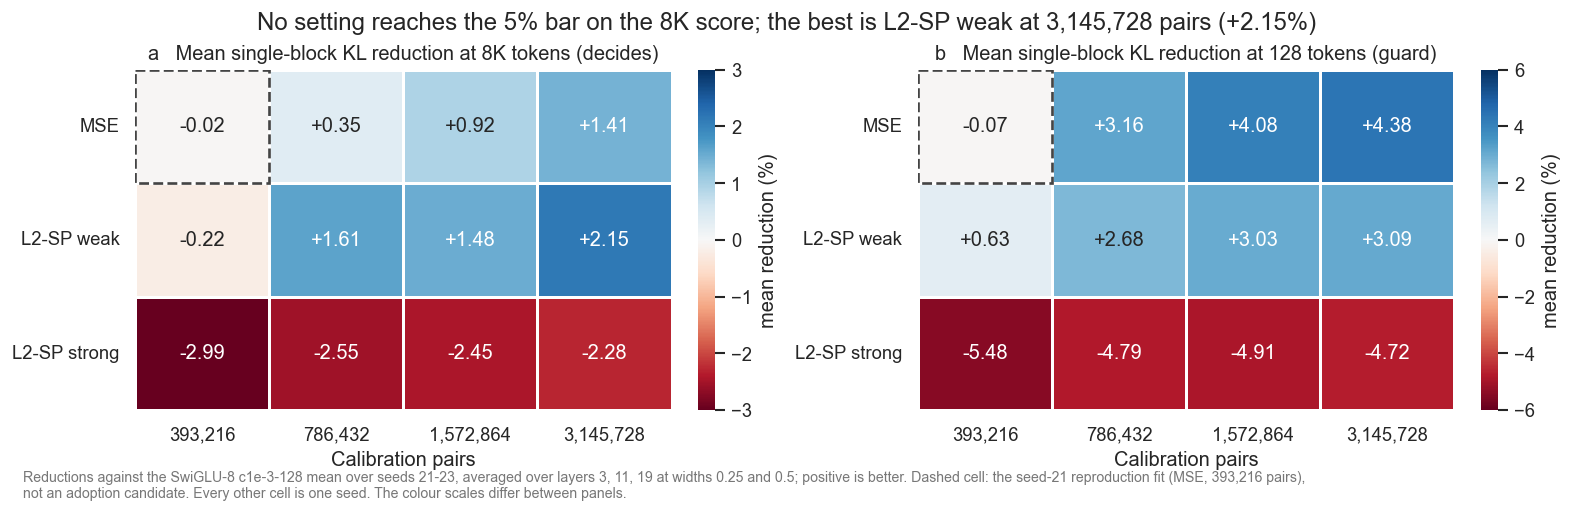

Setting,Loss,Pairs,Mean @ 8K,Mean @ 128,Seed noise,Worst combination,Worst at,Qualifies,Reasons
l2sp-weak-3146k,l2sp-weak,"3,145,728",+2.15%,+3.09%,0.42%,-2.96%,"layer 3, width 0.25, 8K",False,mean 8192-token reduction is not above 5%
l2sp-weak-786k,l2sp-weak,"786,432",+1.61%,+2.68%,0.42%,-1.40%,"layer 3, width 0.25, 8K",False,mean 8192-token reduction is not above 5%
l2sp-weak-1573k,l2sp-weak,"1,572,864",+1.48%,+3.03%,0.42%,-4.88%,"layer 3, width 0.25, 8K",False,mean 8192-token reduction is not above 5%
mse-3146k,mse,"3,145,728",+1.41%,+4.38%,0.42%,-7.27%,"layer 3, width 0.25, 8K",False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
mse-1573k,mse,"1,572,864",+0.92%,+4.08%,0.42%,-8.63%,"layer 3, width 0.25, 8K",False,mean 8192-token reduction is not above 5%; a combination is more than 5% worse
mse-786k,mse,"786,432",+0.35%,+3.16%,0.42%,-8.52%,"layer 3, width 0.25, 8K",False,mean 8192-token reduction is not above 5%; mean reduction is not above the seed noise; a combination is more than 5% worse
l2sp-weak-393k,l2sp-weak,"393,216",-0.22%,+0.63%,0.42%,-4.18%,"layer 3, width 0.25, 8K",False,mean 8192-token reduction is not above 5%; mean reduction is not above the seed noise
l2sp-strong-3146k,l2sp-strong,"3,145,728",-2.28%,-4.72%,0.42%,-10.20%,"layer 19, width 0.5, 128",False,mean 8192-token reduction is not above 5%; mean reduction is not above the seed noise; a combination is more than 5% worse
l2sp-strong-1573k,l2sp-strong,"1,572,864",-2.45%,-4.91%,0.42%,-11.11%,"layer 19, width 0.25, 128",False,mean 8192-token reduction is not above 5%; mean reduction is not above the seed noise; a combination is more than 5% worse
l2sp-strong-786k,l2sp-strong,"786,432",-2.55%,-4.79%,0.42%,-10.93%,"layer 19, width 0.5, 128",False,mean 8192-token reduction is not above 5%; mean reduction is not above the seed noise; a combination is more than 5% worse


In [11]:
figure, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for axis, letter, label in zip(axes, 'ab', ('8K', '128')):
    grid = 100 * setting_df.pivot(index='Loss', columns='Pairs', values=f'Mean @ {label}').loc[list(LOSS_LABELS), SIZES]
    limit = np.ceil(grid.abs().max().max())
    sns.heatmap(grid, ax=axis, cmap='RdBu', center=0, vmin=-limit, vmax=limit, annot=True, fmt='+.2f',
                linewidths=0.8, linecolor='white', cbar_kws={'label': 'mean reduction (%)'},
                xticklabels=[f'{size:,}' for size in SIZES], yticklabels=list(LOSS_LABELS.values()))
    axis.add_patch(Rectangle((0, 0), 1, 1, fill=False, edgecolor=DENSE_COLOR, linewidth=1.6, linestyle='--'))
    axis.set(xlabel='Calibration pairs', ylabel='',
             title=f"{letter}   Mean single-block KL reduction at {label} tokens{' (decides)' if label == '8K' else ' (guard)'}")
    axis.tick_params(axis='y', rotation=0)
best = setting_df[setting_df['Setting'] != REPRODUCTION_SETTING].sort_values('Mean @ 8K').iloc[-1]
figure.suptitle(f"No setting reaches the {ADOPTION_RULE['minimum_mean_reduction']:.0%} bar on the 8K score; the best is "
                f"{LOSS_LABELS[best['Loss']]} at {best['Pairs']:,} pairs ({100 * best['Mean @ 8K']:+.2f}%)")
figure.text(0.01, -0.05, 'Reductions against the SwiGLU-8 c1e-3-128 mean over seeds 21-23, averaged over layers 3, 11, 19 '
            'at widths 0.25 and 0.5; positive is better. Dashed cell: the seed-21 reproduction fit (MSE, 393,216 pairs),\n'
            'not an adoption candidate. Every other cell is one seed. The colour scales differ between panels.',
            fontsize=8.5, color=NOTE_COLOR)
plt.show()

show_table(
    setting_df[setting_df['Setting'] != REPRODUCTION_SETTING].drop(columns=['Overfitting layers', 'Overfitting remains'])
    .sort_values('Mean @ 8K', ascending=False),
    f"Adoption rule (SwiGLU-8, decision log 2026-10-17): mean 8K reduction above {ADOPTION_RULE['minimum_mean_reduction']:.0%} "
    f"and above the seed noise; no combination more than {ADOPTION_RULE['maximum_combination_increase']:.0%} worse at 128 or 8K",
    {'Pairs': '{:,}', 'Mean @ 8K': '{:+.2%}', 'Mean @ 128': '{:+.2%}', 'Seed noise': '{:.2%}', 'Worst combination': '{:+.2%}'},
)

part A, question 4: the stage-2 overfitting indicator against the KL gain

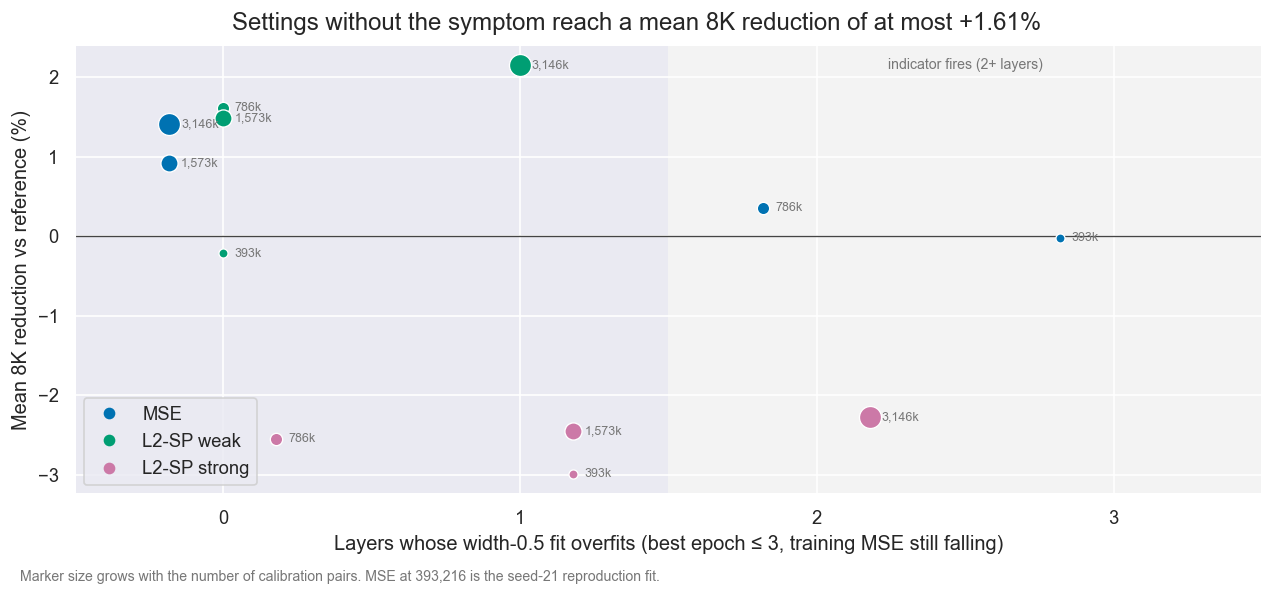

Setting,Loss,Pairs,Overfitting layers,Overfitting remains,Mean @ 8K,Mean @ 128,Best epoch L3,Best epoch L11,Best epoch L19
mse-393k,mse,"393,216","3, 11, 19",True,-0.02%,-0.07%,3,3,3
l2sp-weak-393k,l2sp-weak,"393,216",-,False,-0.22%,+0.63%,11,13,11
l2sp-strong-393k,l2sp-strong,"393,216",11,False,-2.99%,-5.48%,11,3,6
mse-786k,mse,"786,432","3, 19",True,+0.35%,+3.16%,2,10,2
l2sp-weak-786k,l2sp-weak,"786,432",-,False,+1.61%,+2.68%,6,9,10
l2sp-strong-786k,l2sp-strong,"786,432",-,False,-2.55%,-4.79%,6,4,4
mse-1573k,mse,"1,572,864",-,False,+0.92%,+4.08%,5,13,7
l2sp-weak-1573k,l2sp-weak,"1,572,864",-,False,+1.48%,+3.03%,5,8,7
l2sp-strong-1573k,l2sp-strong,"1,572,864",19,False,-2.45%,-4.91%,5,6,1
mse-3146k,mse,"3,145,728",-,False,+1.41%,+4.38%,4,25,6


In [12]:
width_half = fits_df[fits_df['Width ratio'] == 0.5]
indicator_df = setting_df[['Setting', 'Loss', 'Pairs', 'Overfitting layers', 'Overfitting remains', 'Mean @ 8K', 'Mean @ 128']].merge(
    width_half.pivot(index='Setting', columns='Layer', values='Best epoch').rename(columns=lambda layer: f'Best epoch L{layer}')
    .reset_index(), on='Setting')
indicator_df['Overfitting layers'] = indicator_df['Overfitting layers'].map(lambda layers: ', '.join(map(str, layers)) or '-')

figure, axis = plt.subplots(figsize=(10.5, 4.6))
offsets = dict(zip(LOSS_LABELS, (-0.18, 0.0, 0.18)))
for _, row in setting_df.iterrows():
    x = len(row['Overfitting layers']) + offsets[row['Loss']]
    axis.scatter(x, 100 * row['Mean @ 8K'], color=LOSS_COLORS[row['Loss']], s=30 + 25 * np.log2(row['Pairs'] / SIZES[0]) ** 1.6,
                 edgecolor='white', linewidth=0.8, zorder=3)
    axis.annotate(f"{row['Pairs'] / 1e3:,.0f}k", (x, 100 * row['Mean @ 8K']), xytext=(7, 0), textcoords='offset points',
                  va='center', fontsize=7.5, color=NOTE_COLOR)
axis.axhline(0, color=DENSE_COLOR, linewidth=0.8)
axis.axvspan(1.5, 3.5, color='#f3f3f3', linewidth=0, zorder=0)
axis.text(2.5, 0.97, 'indicator fires (2+ layers)', transform=axis.get_xaxis_transform(), ha='center', va='top',
          fontsize=8.5, color=NOTE_COLOR)
axis.set(xticks=range(4), xlim=(-0.5, 3.5), xlabel='Layers whose width-0.5 fit overfits (best epoch ≤ 3, training MSE still falling)',
         ylabel='Mean 8K reduction vs reference (%)')
axis.legend(handles=[Line2D([], [], marker='o', color=color, linestyle='none', label=LOSS_LABELS[loss])
                     for loss, color in LOSS_COLORS.items()], loc='lower left')
cleared = setting_df[setting_df['Overfitting layers'].map(len) == 0]
figure.suptitle(f"Settings without the symptom reach a mean 8K reduction of at most {100 * cleared['Mean @ 8K'].max():+.2f}%")
figure.text(0.01, -0.04, 'Marker size grows with the number of calibration pairs. MSE at 393,216 is the seed-21 reproduction fit.',
            fontsize=8.5, color=NOTE_COLOR)
plt.show()
show_table(indicator_df, 'Stage-2 indicator per setting at width 0.5 (one seed; the indicator fires when two or more layers overfit)',
           {'Pairs': '{:,}', 'Mean @ 8K': '{:+.2%}', 'Mean @ 128': '{:+.2%}'})

part A, question 5: the realized L2-SP pull against the one-dimensional prediction

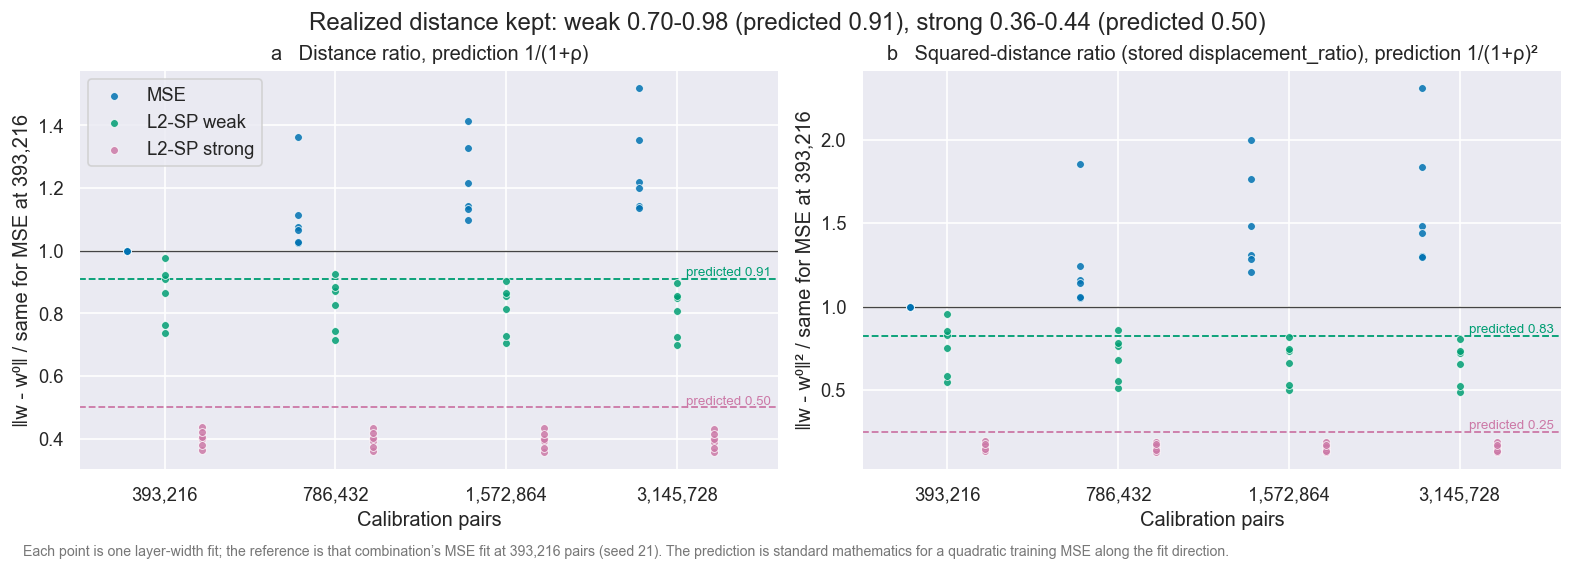

Loss,Pairs,Distance min,Distance max,Squared min,Squared max,Predicted distance,Predicted squared
mse,"393,216",1.00,1.00,1.00,1.00,-,-
l2sp-weak,"393,216",0.74,0.98,0.55,0.95,0.91,0.83
l2sp-strong,"393,216",0.37,0.44,0.13,0.19,0.50,0.25
mse,"786,432",1.02,1.36,1.05,1.86,-,-
l2sp-weak,"786,432",0.72,0.93,0.51,0.86,0.91,0.83
l2sp-strong,"786,432",0.36,0.43,0.13,0.19,0.50,0.25
mse,"1,572,864",1.10,1.41,1.21,2.00,-,-
l2sp-weak,"1,572,864",0.71,0.90,0.50,0.82,0.91,0.83
l2sp-strong,"1,572,864",0.36,0.43,0.13,0.19,0.50,0.25
mse,"3,145,728",1.14,1.52,1.30,2.31,-,-


Layer,Width ratio,ΔMSE (training),d²,α weak,α strong,Largest relative difference to stored α
3,0.25,0.06001,"39,397",3.047e-07,3.047e-06,0.0e+00
3,0.5,0.0374,"20,994",3.563e-07,3.563e-06,0.0e+00
11,0.25,0.3566,"61,833",1.153e-06,1.153e-05,0.0e+00
11,0.5,0.196,"18,747",2.091e-06,2.091e-05,0.0e+00
19,0.25,5.595,"56,117",1.994e-05,1.994e-04,0.0e+00
19,0.5,3.216,"20,807",3.091e-05,3.091e-04,0.0e+00


In [13]:
ratios = {loss: part_a['losses'][loss] for loss in LOSS_LABELS}
figure, axes = plt.subplots(1, 2, figsize=(13, 4.4))
offsets = dict(zip(LOSS_LABELS, (-0.22, 0.0, 0.22)))
for axis, letter, (column, power) in zip(axes, 'ab', (('Distance ratio', 1), ('Squared-distance ratio', 2))):
    for loss, rows in fits_df.groupby('Loss', sort=False):
        positions = rows['Pairs'].map({size: index for index, size in enumerate(SIZES)}) + offsets[loss]
        axis.scatter(positions, rows[column], color=LOSS_COLORS[loss], s=22, alpha=0.85, edgecolor='white', linewidth=0.5,
                     label=LOSS_LABELS[loss], zorder=3)
        if ratios[loss] is not None:
            predicted = (1 / (1 + ratios[loss])) ** power
            axis.axhline(predicted, color=LOSS_COLORS[loss], linestyle='--', linewidth=1.1)
            axis.text(len(SIZES) - 0.45, predicted, f'predicted {predicted:.2f}', color=LOSS_COLORS[loss], fontsize=8,
                      va='bottom', ha='right')
    axis.axhline(1, color=DENSE_COLOR, linewidth=0.8)
    axis.set(xticks=range(len(SIZES)), xticklabels=[f'{size:,}' for size in SIZES], xlim=(-0.5, len(SIZES) - 0.4),
             xlabel='Calibration pairs', title=f'{letter}   ' + ('Distance ratio, prediction 1/(1+ρ)' if power == 1
                                                                 else 'Squared-distance ratio (stored displacement_ratio), prediction 1/(1+ρ)²'))
axes[0].set_ylabel('‖w - w⁰‖ / same for MSE at 393,216')
axes[1].set_ylabel('‖w - w⁰‖² / same for MSE at 393,216')
axes[0].legend(loc='upper left')
pull = fits_df[fits_df['Loss'] != 'mse'].groupby('Loss')['Distance ratio'].agg(['min', 'max'])
figure.suptitle(f"Realized distance kept: weak {pull.loc['l2sp-weak', 'min']:.2f}-{pull.loc['l2sp-weak', 'max']:.2f} "
                f"(predicted {1 / (1 + ratios['l2sp-weak']):.2f}), strong {pull.loc['l2sp-strong', 'min']:.2f}-"
                f"{pull.loc['l2sp-strong', 'max']:.2f} (predicted {1 / (1 + ratios['l2sp-strong']):.2f})")
figure.text(0.01, -0.04, 'Each point is one layer-width fit; the reference is that combination’s MSE fit at 393,216 pairs '
            '(seed 21). The prediction is standard mathematics for a quadratic training MSE along the fit direction.',
            fontsize=8.5, color=NOTE_COLOR)
plt.show()

show_table(
    fits_df.groupby(['Loss', 'Pairs'], sort=False).agg(**{
        'Distance min': ('Distance ratio', 'min'), 'Distance max': ('Distance ratio', 'max'),
        'Squared min': ('Squared-distance ratio', 'min'), 'Squared max': ('Squared-distance ratio', 'max'),
    }).reset_index().assign(**{
        'Predicted distance': lambda frame: frame['Loss'].map(lambda loss: 1 / (1 + ratios[loss]) if ratios[loss] else None),
        'Predicted squared': lambda frame: frame['Loss'].map(lambda loss: 1 / (1 + ratios[loss]) ** 2 if ratios[loss] else None),
    }),
    'Realized pull per setting, over the six layer-width combinations',
    {'Pairs': '{:,}', 'Distance min': '{:.2f}', 'Distance max': '{:.2f}', 'Squared min': '{:.2f}', 'Squared max': '{:.2f}',
     'Predicted distance': '{:.2f}', 'Predicted squared': '{:.2f}'},
)

alpha_rows = []
for layer, widths in calibration.items():
    for width, row in widths.items():
        stored = {loss: row['alpha'][loss] for loss in ('l2sp-weak', 'l2sp-strong')}
        recomputed = {loss: 2 * ratios[loss] * row['training_mse_gain'] / row['squared_distance'] for loss in stored}
        alpha_rows.append({
            'Layer': int(layer), 'Width ratio': int(width) / ORIGINAL_WIDTH, 'ΔMSE (training)': row['training_mse_gain'],
            'd²': row['squared_distance'], 'α weak': recomputed['l2sp-weak'], 'α strong': recomputed['l2sp-strong'],
            'Largest relative difference to stored α': max(relative_difference(recomputed[loss], stored[loss]) for loss in stored),
        })
show_table(pd.DataFrame(alpha_rows), 'α = 2ρ·ΔMSE/d² per combination (project-defined), recomputed from the stored gain and distance',
           {'Width ratio': '{:g}', 'ΔMSE (training)': '{:.4g}', 'd²': '{:,.0f}', 'α weak': '{:.3e}', 'α strong': '{:.3e}',
            'Largest relative difference to stored α': '{:.1e}'})

part A, question 6: layer 3 at width 0.25 against the other combinations (MSE)

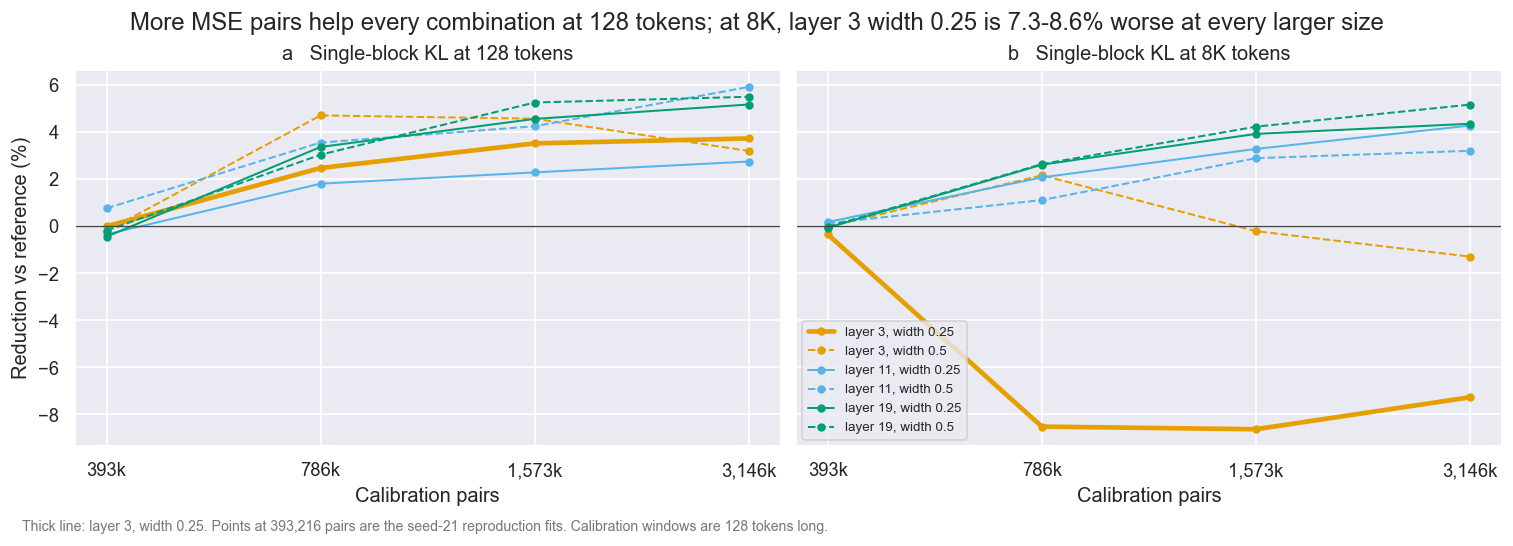

Layer,Width ratio,Reference mean @ 128,Reference mean @ 8K,"KL @ 128, 393,216","KL @ 128, 786,432","KL @ 128, 1,572,864","KL @ 128, 3,145,728","KL @ 8K, 393,216","KL @ 8K, 786,432","KL @ 8K, 1,572,864","KL @ 8K, 3,145,728"
3,0.25,0.02690,0.04082,0.02690,0.02624,0.02596,0.02590,0.04096,0.04430,0.04435,0.04379
3,0.5,0.01454,0.01950,0.01457,0.01386,0.01388,0.01408,0.01950,0.01907,0.01954,0.01975
11,0.25,0.01707,0.02369,0.01713,0.01676,0.01668,0.01660,0.02365,0.02320,0.02291,0.02268
11,0.5,0.00942,0.01260,0.00935,0.00908,0.00902,0.00886,0.01258,0.01246,0.01223,0.01219
19,0.25,0.04252,0.05544,0.04271,0.04109,0.04058,0.04032,0.05547,0.05398,0.05326,0.05302
19,0.5,0.02092,0.02792,0.02096,0.02029,0.01982,0.01977,0.02793,0.02718,0.02674,0.02648


In [14]:
mse = fits_df[fits_df['Loss'] == 'mse'].sort_values('Pairs')
layer_colors = dict(zip(sorted(fits_df['Layer'].unique()), ('#E69F00', '#56B4E9', '#009E73')))
figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for axis, letter, label in zip(axes, 'ab', ('128', '8K')):
    for (layer, width), rows in mse.groupby(['Layer', 'Width']):
        highlighted = (layer, width) == (3, 2048)
        axis.plot(rows['Pairs'], 100 * rows[f'Reduction @ {label}'], color=layer_colors[layer], marker='o', markersize=4,
                  linestyle='-' if width == 2048 else '--', linewidth=2.8 if highlighted else 1.2,
                  label=f'layer {layer}, width {width / ORIGINAL_WIDTH:g}')
    axis.axhline(0, color=DENSE_COLOR, linewidth=0.8)
    axis.set(xscale='log', xlabel='Calibration pairs', title=f'{letter}   Single-block KL at {label} tokens')
    axis.xaxis.set_major_locator(FixedLocator(SIZES))
    axis.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1e3:,.0f}k'))
    axis.xaxis.set_minor_locator(NullLocator())
axes[0].set_ylabel('Reduction vs reference (%)')
axes[1].legend(loc='lower left', fontsize=8)
layer3 = mse[(mse['Layer'] == 3) & (mse['Width'] == 2048) & (mse['Pairs'] > SIZES[0])]
figure.suptitle(f"More MSE pairs help every combination at 128 tokens; at 8K, layer 3 width 0.25 is "
                f"{-100 * layer3['Reduction @ 8K'].max():.1f}-{-100 * layer3['Reduction @ 8K'].min():.1f}% worse at every larger size")
figure.text(0.01, -0.04, 'Thick line: layer 3, width 0.25. Points at 393,216 pairs are the seed-21 reproduction fits. '
            'Calibration windows are 128 tokens long.', fontsize=8.5, color=NOTE_COLOR)
plt.show()

combination_table = reference_summary[['Layer', 'Width', 'Reference mean @ 128', 'Reference mean @ 8K']].copy()
for label in CONTEXTS.values():
    for pairs in SIZES:
        values = mse[mse['Pairs'] == pairs].set_index(['Layer', 'Width'])[f'KL @ {label}']
        combination_table[f'KL @ {label}, {pairs:,}'] = [values.loc[(layer, width)] for layer, width in
                                                         zip(combination_table['Layer'], combination_table['Width'])]
combination_table.insert(1, 'Width ratio', combination_table.pop('Width') / ORIGINAL_WIDTH)
show_table(combination_table, 'Absolute single-block KL for MSE fits by calibration pairs, with the SwiGLU-8 reference mean',
           {column: '{:.5f}' for column in combination_table.columns if column.startswith(('KL', 'Reference'))}
           | {'Width ratio': '{:g}'})

cross-check: recomputed values against the stored summaries

In [15]:
def compare(artifact, quantity, recomputed, stored):
    recomputed = np.asarray([np.nan if value is None else value for value in recomputed], dtype=float)
    stored = np.asarray([np.nan if value is None else value for value in stored], dtype=float)
    present = ~np.isnan(recomputed) & ~np.isnan(stored)
    difference = np.abs(recomputed[present] - stored[present])
    relative = np.divide(difference, np.abs(stored[present]), out=np.zeros_like(difference), where=stored[present] != 0)
    return {'Artifact': artifact, 'Quantity': quantity, 'Values': len(stored),
            'Largest absolute difference': difference.max(initial=0.0), 'Largest relative difference': relative.max(initial=0.0),
            'Bitwise equal': bool((np.isnan(recomputed) == np.isnan(stored)).all() and not difference.any())}


def compare_labels(artifact, quantity, recomputed, stored):
    return {'Artifact': artifact, 'Quantity': quantity, 'Values': len(stored), 'Largest absolute difference': None,
            'Largest relative difference': None, 'Bitwise equal': list(recomputed) == list(stored)}


stored_targets = {float(target): row for target, row in summary_results['targets'].items()}
verdict_by_target = verdict_df.set_index('Target')
summary_name = 'part-b-summary-001'
check_rows = [
    compare(summary_name, 'g at 1B', verdict_by_target['g @ 1B'], [stored_targets[t]['gap'] for t in TARGETS]),
    compare(summary_name, 'Fitted 8K KL', verdict_by_target['8K KL fitted'], [stored_targets[t]['fitted_teacher_kl_8192'] for t in TARGETS]),
    compare(summary_name, 'Slice-only 8K KL', verdict_by_target['8K KL slice only'], [stored_targets[t]['slice_teacher_kl_8192'] for t in TARGETS]),
    compare_labels(summary_name, 'Verdict', verdict_by_target['Verdict'], [stored_targets[t]['verdict'] for t in TARGETS]),
    compare(summary_name, 'Twin noise', [twin_noise], [summary_results['noise']['value']]),
    compare(summary_name, 'Twin noise points', noise_df['Relative difference'],
            [point['relative_difference'] for point in summary_results['noise']['points']]),
    compare(summary_name, 'g at 50% with the twin', [twin_gap], [summary_results['twin']['gap_with_twin_at_0.5']]),
    compare(summary_name, 'Closing point (tokens)', verdict_by_target['Closing point'],
            [stored_targets[t]['closing_point_tokens'] for t in TARGETS]),
    compare(summary_name, 'Gap-curve tokens', curve_df['Tokens'],
            [row['tokens'] for t in TARGETS for row in stored_targets[t]['gap_curve']]),
    compare(summary_name, 'Gap curve: fitted, slice, gap', curve_df[['Fitted KL', 'Slice KL', 'Gap']].to_numpy().ravel(),
            [row[key] for t in TARGETS for row in stored_targets[t]['gap_curve'] for key in ('fitted', 'slice', 'gap')]),
    compare(summary_name, 'Raw token equivalents', equivalent_df['Raw equivalent'],
            [row['slice_tokens'] for t in TARGETS for row in stored_targets[t]['token_equivalent']]),
    compare(summary_name, 'Twin final perplexity differences',
            [row['Difference'] for row in twin_rows if row['Quantity'].startswith('Perplexity')],
            [row['relative_difference'] for _, row in sorted(summary_results['twin']['final_evaluation_differences']['perplexity'].items())]),
    compare(summary_name, 'Twin task and macro differences (pp)',
            [row['Difference'] for row in twin_rows if '(pp)' in row['Quantity']],
            [100 * row['difference'] for _, row in sorted(summary_results['twin']['final_evaluation_differences']['task_accuracy'].items())]
            + [100 * summary_results['twin']['final_evaluation_differences']['macro_accuracy_difference']]),
]

block_name = 'block-check-001'
adoption = block_results['adoption']
stored_reference = {(row['layer'], row['width'], row['context']): row for row in adoption['reference_seed_summaries']}
reference_long = [(row['Layer'], row['Width'], context, row[f'Reference mean @ {label}'], row[f'Reference SD @ {label}'])
                  for _, row in reference_summary.iterrows() for context, label in CONTEXTS.items()]
candidates = setting_df[setting_df['Setting'] != REPRODUCTION_SETTING].set_index('Setting').loc[list(adoption['settings'])]
reduction_long = fits_df.set_index(['Setting', 'Layer', 'Width'])
check_rows += [
    compare(block_name, 'Reference seed means', [row[3] for row in reference_long],
            [stored_reference[row[:3]]['mean'] for row in reference_long]),
    compare(block_name, 'Reference seed SDs', [row[4] for row in reference_long],
            [stored_reference[row[:3]]['seed_sd'] for row in reference_long]),
    compare(block_name, 'Per-combination reductions',
            [reduction_long.loc[(setting, row['layer'], row['width']), f"Reduction @ {CONTEXTS[row['context']]}"]
             for setting, stored in adoption['settings'].items() for row in stored['reductions']],
            [row['reduction'] for stored in adoption['settings'].values() for row in stored['reductions']]),
    compare(block_name, 'Mean reductions (8K, 128)', candidates[['Mean @ 8K', 'Mean @ 128']].to_numpy().ravel(),
            [stored['mean_reduction'][str(context)] for stored in adoption['settings'].values() for context in (8192, 128)]),
    compare(block_name, 'Mean seed noise', candidates['Seed noise'], [stored['mean_seed_noise'] for stored in adoption['settings'].values()]),
    compare(block_name, 'Worst combination', candidates['Worst combination'],
            [stored['worst_reduction'] for stored in adoption['settings'].values()]),
    compare_labels(block_name, 'Qualifies', candidates['Qualifies'], [stored['qualifies'] for stored in adoption['settings'].values()]),
    compare_labels(block_name, 'Reasons', candidates['Reasons'],
                   ['; '.join(stored['reasons']) or '-' for stored in adoption['settings'].values()]),
    compare_labels(block_name, 'Stage-2 overfitting layers', setting_df.set_index('Setting')['Overfitting layers'].map(list),
                   [block_results['stage_two_indicator'][setting]['overfitting_layers'] for setting in setting_df['Setting']]),
    compare(block_name, 'α (weak, strong)', [row[key] for row in alpha_rows for key in ('α weak', 'α strong')],
            [calibration[str(row['Layer'])][str(int(row['Width ratio'] * ORIGINAL_WIDTH))]['alpha'][loss]
             for row in alpha_rows for loss in ('l2sp-weak', 'l2sp-strong')]),
    compare(block_name, 'Displacement ratio (squared)', fits_df['Squared-distance ratio'], fits_df['Stored ratio']),
]
show_table(pd.DataFrame(check_rows), 'Recomputed in this notebook against the values stored by the workflow '
           '(differences near 1e-14 are floating-point summation order)',
           {'Largest absolute difference': '{:.2e}', 'Largest relative difference': '{:.2e}'})

Artifact,Quantity,Values,Largest absolute difference,Largest relative difference,Bitwise equal
part-b-summary-001,g at 1B,3,8.02e-17,2.40e-14,False
part-b-summary-001,Fitted 8K KL,3,0.00e+00,0.00e+00,True
part-b-summary-001,Slice-only 8K KL,3,0.00e+00,0.00e+00,True
part-b-summary-001,Verdict,3,-,-,True
part-b-summary-001,Twin noise,1,0.00e+00,0.00e+00,True
part-b-summary-001,Twin noise points,22,0.00e+00,0.00e+00,True
part-b-summary-001,g at 50% with the twin,1,3.12e-17,1.73e-15,False
part-b-summary-001,Closing point (tokens),3,0.00e+00,0.00e+00,True
part-b-summary-001,Gap-curve tokens,126,0.00e+00,0.00e+00,True
part-b-summary-001,"Gap curve: fitted, slice, gap",378,2.22e-16,5.38e-14,False


acceptance checks

In [16]:
acceptance_df['Relative difference'] = pd.to_numeric(acceptance_df['Relative difference'], errors='coerce')
acceptance_df['Tolerance'] = pd.to_numeric(acceptance_df['Tolerance'], errors='coerce')
show_table(
    acceptance_df.groupby(['Stage', 'Group'], sort=False).agg(
        Checks=('Passed', 'size'), **{'Within tolerance': ('Passed', 'sum'),
                                      'Largest relative difference': ('Relative difference', 'max'),
                                      'Tolerance': ('Tolerance', 'max')},
    ).reset_index(),
    'D1-D2 data and ranking, P5 teacher against itself, A1-A3 slices and the reproduction fit, P4 recovery stream, '
    'C1/B1 exact at token 0; C2/B2 reviewed against 1%',
    {'Largest relative difference': '{:.2e}', 'Tolerance': '{:.0e}'},
)
flagged = acceptance_df[~acceptance_df['Passed']]
show_table(flagged[['Stage', 'Run', 'Group', 'Metric', 'Tokens', 'Value', 'Reference', 'Relative difference', 'Tolerance']],
           'Values outside tolerance (review values, not stops): the slice-only 50% transient at 50M',
           {'Tokens': '{:,.0f}', 'Value': '{:.6f}', 'Reference': '{:.6f}', 'Relative difference': '{:.2%}', 'Tolerance': '{:.0%}'})

Stage,Group,Checks,Within tolerance,Largest relative difference,Tolerance
Part A block check,D1,21,21,-,-
Part A block check,P5,3,3,-,1e-06
Part A block check,D2,3,3,-,-
Part A block check,A1,6,6,0.00e+00,1e-04
Part A block check,A2-A3,24,24,0.00e+00,1e-03
Reference KL,P5,1,1,-,1e-06
Part B recovery,P4,5,5,-,-
Part B recovery,C1,10,10,0.00e+00,1e-04
Part B recovery,B1,2,2,0.00e+00,1e-04
Part B recovery,C2,45,43,4.37e-01,1e-02


Stage,Run,Group,Metric,Tokens,Value,Reference,Relative difference,Tolerance
Part B recovery,slice 50%,C2,recovery_validation_kl,"50,003,968",0.391289,0.272243,43.73%,1%
Part B recovery,slice 50%,C2,wikitext_validation_perplexity,"50,003,968",25.793545,22.976486,12.26%,1%


compute and deployment (workflow timing proxy; scheduler records in docs/infrastructure/perun/perun-log.md)

In [17]:
block_tasks = block_results['tasks']
train_hours = [workflow_hours(run) for run in runs.values()]
stage_rows = [
    ('A: block check', 'block-check', [workflow_hours(task) for task in block_tasks]),
    ('B: recovery runs', 'train', train_hours),
    ('B: reference KL', 'reference-kl', [workflow_hours(reference_kl)]),
]
stage_df = pd.DataFrame([
    {'Stage': stage, 'Jobs': len(hours), 'Time limit (h)': REQUESTED_HOURS[key],
     'Planned GPU-h': '{:g}-{:g}'.format(*PLANNED_GPU_HOURS[key]), 'Measured GPU-h (proxy)': sum(hours),
     'Longest job (h)': max(hours), 'CPU core-h (proxy)': CPUS_PER_JOB * sum(hours), 'RAM requested (GB)': REQUESTED_RAM_GB[key]}
    for stage, key, hours in stage_rows
])
planned_total = [sum(bounds) for bounds in zip(*PLANNED_GPU_HOURS.values())]
show_table(stage_df, f"Measured {stage_df['Measured GPU-h (proxy)'].sum():.1f} GPU-h (workflow timing, one H200 per job) "
           f'against a plan of {planned_total[0]:g}-{planned_total[1]:g} GPU-h',
           {'Measured GPU-h (proxy)': '{:.2f}', 'Longest job (h)': '{:.2f}', 'CPU core-h (proxy)': '{:.1f}'})

recovery_runs = [run['results']['recovery'] for run in runs.values()]
run_metrics = {
    'Training (h)': [recovery['training_seconds'] / 3600 for recovery in recovery_runs],
    'Final evaluation (h)': [run['results']['final_evaluation_wall_seconds'] / 3600 for run in runs.values()],
    'Checkpointing (h)': [recovery['checkpoint_seconds'] / 3600 for recovery in recovery_runs],
    'Workflow span (h)': train_hours,
    'Training throughput (tokens/s per H200)': [recovery['tokens_seen'] / recovery['training_seconds'] for recovery in recovery_runs],
    'Peak RAM (GiB)': [recovery['memory']['peak_ram_gib'] for recovery in recovery_runs],
    'Peak VRAM (GiB)': [recovery['memory']['peak_vram_gib'] for recovery in recovery_runs],
    'Bundle (GiB)': [run['results']['evaluation']['footprint']['bundle_bytes'] / 2**30 for run in runs.values()],
}
requests = {'Workflow span (h)': f"{REQUESTED_HOURS['train']} h limit", 'Peak RAM (GiB)': f"{REQUESTED_RAM_GB['train']} GB requested",
            'Peak VRAM (GiB)': '141 GB H200'}
show_table(pd.DataFrame([
    {'Per recovery run': name, 'Min': min(values), 'Max': max(values), 'Request': requests.get(name, '-')}
    for name, values in run_metrics.items()
]), f"{len(runs)} recovery runs; {sum(run_metrics['Bundle (GiB)']):.1f} GiB of BF16 bundles on PROJECT",
   {'Min': '{:,.2f}', 'Max': '{:,.2f}'})

artifacts = {'block check': block_check, 'reference KL': reference_kl,
             **{f'{arm} {target:.0%}': run for (arm, target), run in runs.items()}}
print(f"Artifacts with a recorded error: {sum(artifact.get('error') is not None for artifact in artifacts.values())} "
      f'of {len(artifacts)}; failures and retries are logged in perun-log.md')
print('Unknown from the artifacts: scheduler allocation and queue time (sacct disabled), CPU and GPU utilization, '
      'peak SCRATCH, block-check and reference-KL peak memory')
show_table(pd.DataFrame([
    {'Artifact': name, 'Python': artifact['environment']['python'], 'PyTorch': artifact['environment']['packages']['torch'],
     'Transformers': artifact['environment']['packages']['transformers'], 'lm-eval': artifact['environment']['packages']['lm_eval'],
     'CUDA runtime': artifact['environment']['cuda_runtime'], 'GPU': artifact['environment']['gpu']}
    for name, artifact in artifacts.items()
]).drop_duplicates(subset=['Python', 'PyTorch', 'Transformers', 'lm-eval', 'CUDA runtime', 'GPU']),
   'Distinct software and hardware environments')

Stage,Jobs,Time limit (h),Planned GPU-h,Measured GPU-h (proxy),Longest job (h),CPU core-h (proxy),RAM requested (GB)
A: block check,3,6,2.5-7,5.43,2.69,43.5,128
B: recovery runs,5,14,48-55,50.02,10.62,400.2,64
B: reference KL,1,1,0.1-0.3,0.03,0.03,0.2,64


Per recovery run,Min,Max,Request
Training (h),9.03,10.23,-
Final evaluation (h),0.23,0.26,-
Checkpointing (h),0.07,0.15,-
Workflow span (h),9.37,10.62,14 h limit
Training throughput (tokens/s per H200),"27,153.46","30,751.36",-
Peak RAM (GiB),5.90,8.92,64 GB requested
Peak VRAM (GiB),25.11,31.31,141 GB H200
Bundle (GiB),1.54,2.78,-


Artifacts with a recorded error: 0 of 7; failures and retries are logged in perun-log.md
Unknown from the artifacts: scheduler allocation and queue time (sacct disabled), CPU and GPU utilization, peak SCRATCH, block-check and reference-KL peak memory


Artifact,Python,PyTorch,Transformers,lm-eval,CUDA runtime,GPU
block check,3.12.14,2.11.0+cu128,5.14.1,0.4.13,12.8,NVIDIA H200
